## 0. SETUP

We use the venv from the tutorial and will install any additional dependencies here without modifying the provided requirements.txt. Mirroring the tutorial:


In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# like the tutorial make part 1 modules importable
import sys
from pathlib import Path
 
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1
from part1 import clslib, experiment, loglin, smlp, analysis, utils, bpe

In [ ]:
import numpy as np

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

# The order below fixes our integer<->name mapping for the whole project which is our deliberate choice
snli_outcome_space = clslib.NamedClasses(['entailment', 'neutral', 'contradiction'])
print(snli_outcome_space)

0: entailment, 1: neutral, 2: contradiction


## 1. Load dataset


In [4]:
from datasets import load_dataset

snli = load_dataset("stanfordnlp/snli")
print(snli)

README.md:   0%|          | 0.00/16.0k [00:00<?, ?B/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\admin\.cache\huggingface\hub\datasets--stanfordnlp--snli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Li

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  412kB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  413kB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/550152 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 550152
    })
})


We inspect the dataset as follows:

In [5]:
ex = snli["train"][0]
print("Fields:", list(ex.keys()))
print("premise   :", ex["premise"])
print("hypothesis:", ex["hypothesis"])
print("label (id):", ex["label"])
print()
print("Label feature:", snli["train"].features["label"])

Fields: ['premise', 'hypothesis', 'label']
premise   : A person on a horse jumps over a broken down airplane.
hypothesis: A person is training his horse for a competition.
label (id): 1

Label feature: ClassLabel(names=['entailment', 'neutral', 'contradiction'])


It is important to check this mapping is in alignment with the one we chose to implement so we do not need to do any remappings. Confirmed!

## 1.1 Check for "Bad Data":

1. The HF card mentions that when human annotators could not agree on a label, they default to -1. We need to inspect them and drop them



In [6]:
from collections import Counter

for split in ["train", "validation", "test"]:
    counts = Counter(snli[split]["label"])
    n = len(snli[split])
    n_bad = counts.get(-1, 0)
    print(f"{split:11s} | total {n:>7d} | unlabeled(-1): {n_bad:>5d} | "
          f"dist (0/1/2): {counts.get(0,0)}/{counts.get(1,0)}/{counts.get(2,0)}")

train       | total  550152 | unlabeled(-1):   785 | dist (0/1/2): 183416/182764/183187
validation  | total   10000 | unlabeled(-1):   158 | dist (0/1/2): 3329/3235/3278
test        | total   10000 | unlabeled(-1):   176 | dist (0/1/2): 3368/3219/3237


Also immediate observation: class balance which makes using accuracy defensible.


2. Check for empty strings, non-strings/None, exact duplicates and degenerate pairs

In [7]:
for split in ["train", "validation", "test"]:
    prem = snli[split]["premise"]
    hyp  = snli[split]["hypothesis"]
    n = len(prem)

    # non-string or None entries
    bad_type_p = sum(not isinstance(p, str) for p in prem)
    bad_type_h = sum(not isinstance(h, str) for h in hyp)

    # empty / whitespace-only after stripping
    empty_p = sum(isinstance(p, str) and p.strip() == "" for p in prem)
    empty_h = sum(isinstance(h, str) and h.strip() == "" for h in hyp)

    # premise identical to hypothesis (degenerate pair)
    identical = sum(p == h for p, h in zip(prem, hyp))

    print(f"{split:11s} | n={n:>7d} | "
          f"non-str p/h: {bad_type_p}/{bad_type_h} | "
          f"empty p/h: {empty_p}/{empty_h} | "
          f"premise==hypothesis: {identical}")

train       | n= 550152 | non-str p/h: 0/0 | empty p/h: 0/0 | premise==hypothesis: 309
validation  | n=  10000 | non-str p/h: 0/0 | empty p/h: 0/0 | premise==hypothesis: 4
test        | n=  10000 | non-str p/h: 0/0 | empty p/h: 0/0 | premise==hypothesis: 0


!! flag result: if premise and hypothesis are the exact same sentence, the logically correct label is entailment (a sentence trivially entails itself). Which tells us these are either correctly labeled entailment and harmless, or labeled something else, in which case they’re mislabeled or they’re the degenerate artifact cases and we have to handle them. check:

In [8]:
# What labels do the identical-pair examples carry?
from collections import Counter
identical_labels = [ex["label"] for ex in snli["train"]
    if ex["label"] != -1 and ex["premise"] == ex["hypothesis"]]
print(Counter(identical_labels))  # 0=entail, 1=neutral, 2=contradiction

Counter({0: 267, 1: 25, 2: 17})


- 267 of the 309 identical pairs are entailment (label 0) which is the logically correct label sinc a sentence entails itself. The25 neutral and 17 contradiction where premise and hypothesis are character-for-character identical, these are by definition label noise. -> Remove
- Strategic note! If we do the headline extension about models exploiting shortcuts instead of doing inference, the single strongest shortcut imaginable is “premise and hypothesis share words → entailment,” and we have at the ready 267 examples where total overlap goes with entailment -> we have a ready overlap heuristic. When we later show that overlap-based features push toward entailment, these identical pairs are the limiting case of exactly that pattern.  

3. Because BPE pretokenizer splits on whitespace, this means a "sentence" that tokenizes to nothing (e.g. only punctuation/whitespace) would produce an all-zero feature vectorso we check the extremes of length so we know the range we're dealing with. ie we are making the assumption that each text tokenizes to at least one token so we have to confirm 

In [9]:

import numpy as np

for split in ["train"]:
    lens_p = np.array([len(p.split()) for p in snli[split]["premise"]])
    lens_h = np.array([len(h.split()) for h in snli[split]["hypothesis"]])
    print(f"premise words   : min={lens_p.min()}, median={int(np.median(lens_p))}, max={lens_p.max()}")
    print(f"hypothesis words: min={lens_h.min()}, median={int(np.median(lens_h))}, max={lens_h.max()}")
    print("premises with 0 words   :", int((lens_p == 0).sum()))
    print("hypotheses with 0 words :", int((lens_h == 0).sum()))

premise words   : min=2, median=12, max=78
hypothesis words: min=1, median=7, max=56
premises with 0 words   : 0
hypotheses with 0 words : 0


## 1.2 Stratified Subsampling Decision:



We train on a stratified 40k subsample of SNLI's ~549k training pairs rather than the
full set. The size sits at the intersection of three levers.

**1. Statistical resolution (lower bound).** Our Bayesian comparison operates on
per-fold accuracies, so each validation fold must be large enough that its accuracy
estimate isn't dominated by sampling noise,otherwise the ROPE verdicts become
unresolvable. With 40k and 5-fold CV, each validation fold holds ~8k examples. At an
expected accuracy around 0.75, the standard error on fold accuracy is
√(0.75·0.25 / 8000) ≈ 0.0048 so about half a percentage point, the same order as our
0.005 ROPE. Fold-level noise should be comparable
to or smaller than the ROPE. If we go lower, at only 1k
per fold for example the SE would be ≈ 0.014, roughly three times the ROPE, and most comparisons
would return "can't tell."

**2. Computational tractability (upper bound).** The grid is 9 systems × 5 folds ×
several seeds, plus extensions, and the MLP dominates runtime. The tutorial reports
~20 min for a single 5-fold MLP run on 120k AG News examples and at ~1/3 the data, 40k
puts an MLP run near 6–8 min and the full grid around an afternoon per seed. The full
~550k set would push repeated runs into overnight territory, which is impractical.

**3. Diminishing returns (the SNLI-specific hypothesis).** Bowman et al. (2015) show in
their learning-curve analysis that simple models (feature-rich lexicalized classifiers)
flatten out well before the full corpus, while neural models are the ones that keep improving
with more data. Since our required grid uses simple models (log-linear, shallow MLP),
40k places us on the flat part of their learning curve: we hypothesize that the remaining ~500k examples
would add little accuracy for these model classes while costing ~10× the compute (this is a hypothesis we will be testing)

**Together:** statistics says don't go far below ~20–40k (or the ROPE can't resolve
anything), compute says don't go far above ~50k (or the grid stops being re-runnable),
and the SNLI learning curve says above ~40k we pay for accuracy these simple models
won't gain. 40k is where all three agree.

IF time permits we can include the learning-curve experiment (grid run at 10k / 20k /
40k) testing it directly, serving simultaneously as empirical justification of the
working-set size, a replication of a published SNLI finding, and the
sample-size sensitivity check our Bayesian analysis needs.

In [10]:
from sklearn.model_selection import train_test_split

WORKING_SET_SIZE = 40_000
SUBSAMPLE_SEED = 0  # fixed for reproducibility 

# Drop the -1 examples keep (premise, hypothesis, label) 
# and also we decide to drrop identical-pair mislabels
# (premise == hypothesis but label != entailment) which does not make logical sense and is pure noise
train_pairs_all = [
    ((ex["premise"], ex["hypothesis"]), ex["label"])
    for ex in snli["train"]
    if ex["label"] != -1
    and not (ex["premise"] == ex["hypothesis"] and ex["label"] != 0)
]
print(f"Train pairs after dropping -1 and mislabelled identical examples: {len(train_pairs_all)}")

# Stratified subsample to the working-set size (preserves the balanced label dist).
X = [ph for ph, _ in train_pairs_all]
y = [lab for _, lab in train_pairs_all]

X_work, _, y_work, _ = train_test_split(
    X, y,
    train_size=WORKING_SET_SIZE,
    stratify=y,
    random_state=SUBSAMPLE_SEED,
)

# Reassemble into the ((premise, hypothesis), label) list we'll feed to CV.
working_set = list(zip(X_work, y_work))

#check: size + label distribution preserved.
from collections import Counter
print(f"Working set size: {len(working_set)}")
print("Label dist (0/1/2):", dict(sorted(Counter(y_work).items())))

Train pairs after dropping -1 and mislabelled identical examples: 549325
Working set size: 40000
Label dist (0/1/2): {0: 13356, 1: 13306, 2: 13338}


In [11]:
# Check whether the length distribution is affected by subsampling 

def length_statistics(pairs, label):
	premise_lens = np.array([len(p.split()) for (p, h), _ in pairs])
	hypoth_lens = np.array([len(h.split()) for (p, h), _ in pairs])

	print(f"{label}")
	print(f"premise words: mean={premise_lens.mean():.2f}  median={int(np.median(premise_lens))}  max={premise_lens.max()}")
	print(f"hypothesis words: mean={hypoth_lens.mean():.2f}  median={int(np.median(hypoth_lens))}  max={hypoth_lens.max()}")

length_statistics(train_pairs_all, "FULL set")
length_statistics(working_set, "WORKING SET (40,000)")

FULL set
premise words: mean=12.85  median=12  max=78
hypothesis words: mean=7.42  median=7  max=56
WORKING SET (40,000)
premise words: mean=12.87  median=12  max=78
hypothesis words: mean=7.43  median=7  max=40


## 1.3 Train the BPE tokenizer

Why BPE: 
1. To assist with the controlled comparison against tutorial pipeline, avoid confounds added by different tokenizer.
2. Handling of out-of-vocabulary holes gracefully (no need for UNK character)
3. We do need to consider the following weakness: BPE is frequency motivated not linguistically so an informed tokenizer such as NLTK from the tutorial has the added advantage that it can produce interpretable features which is a bonus for our analysis with negation words, generic words etc. There is a genuine counter-argument that a modestly sized BPE vocab will still keep common whole words like “not” intact bc they’re frequent enough to survive as single tokens, but we would rather verify.

### Vocabulary size sweep

The tutorial used `vocab_size=1000, min_frequency=2`but rather than inheriting these
unquestioned, we choose `vocab_size` from the data. We treat it as a documented
design decision backed by a shorrt sensitivity check, not as a model hyperparameter to
optimize because the tokenizer is a controlled constant for our representation/architecture
comparison, so tuning it per-fold would undermine that control. (also add a computational overhead we cannot afford)

`min_frequency` is a minor lever at our corpus scale (~1.1M sentences) eg a 2 vs. 5 option trims
mainly some noise merges so we fix it at 2 and do not sweep it.

`vocab_size` is the important lever we focus on because it sets our feature dimensionality and 
how aggressively words are split into sub-pieces. it affects performance and the
interpretability for our artifact analysis (if negation words like "not" or
generic words like "person" fragment, the word-level bias signal becomes unclear).

We sweep `vocab_size` over {500, 1000, 2000, 4000, 8000} and measure three
tokenizer-level properties:

- **Avg tokens per sentence** aka how much splitting happens. We look for where this
  curve flattens because beyond that point, extra vocabulary buys little.
- **Artifact-word survival** the fraction of Gururangan et al.'s cue words that
  encode to a single whole token, since we want these intact for the bias analysis.
- **UNK rate** fraction of tokens mapped to the unknown token on held-out text.

We pick the smallest `vocab_size` where fragmentation has levelled off and the cue
words survive whole, then fix it for the entire grid. (we can do ROPE check later to
confirm the grid's conclusions are stable to this choice.)

In [12]:
import numpy as np
from part1.experiment import train_tokenizer

META = "\u2581"  # from the tutorial's pretokenizer

# Cue words from Gururangan (2018) whose survival as whole tokens we care about.
ARTIFACT_WORDS = [
    "not", "no", "never", "nobody", "nothing",            # negation contradiction
    "animal", "outdoors", "outside", "instrument",         # generic entailment
    "person", "people", "tall", "first", "sad", "happy",   # mixed cues
]

# Train BPE on the FULL post-filter set  
sweep_corpus = []
for (prem, hyp), _ in train_pairs_all:
    sweep_corpus.append(prem)
    sweep_corpus.append(hyp)

# Held-out text for the UNK rate:  measure on sentences the tokenizer was NOT trained on. 
heldout_sents = []
for ex in snli["validation"]:
    if ex["label"] != -1:
        heldout_sents.append(ex["premise"])
        heldout_sents.append(ex["hypothesis"])

# Sample the held-out text so the UNK pass is fast.
rng = np.random.default_rng(0)
heldout_sample = list(rng.choice(heldout_sents, size=4000, replace=False))

MIN_FREQ = 2
VOCAB_GRID = [500, 1000, 2000, 4000, 8000]

print(f"{'vocab':>6} | {'actual':>6} | {'avg tok/sent':>12} | {'cue survival':>12} | {'UNK rate':>8}") 

sweep_results = {}
for vs in VOCAB_GRID:
    tok = train_tokenizer(sweep_corpus, vs, MIN_FREQ)
    v = tok.get_vocab()

    # average tokens per sentence on a sample of the training text
    sample = sweep_corpus[:8000]
    tok_counts = [len(tok.encode(s).tokens) for s in sample]
    avg_tok = float(np.mean(tok_counts))

    # artifact-word survival encodes to exactly one token
    survived = sum(len(tok.encode(w).tokens) == 1 for w in ARTIFACT_WORDS)
    survival = survived / len(ARTIFACT_WORDS)

    # UNK rate on held-out dev text
    unk_id = v.get("[UNK]")
    total, unk = 0, 0
    for s in heldout_sample:
        ids = tok.encode(s).ids
        total += len(ids)
        if unk_id is not None:
            unk += sum(1 for i in ids if i == unk_id)
    unk_rate = (unk / total) if total else 0.0

    sweep_results[vs] = (len(v), avg_tok, survival, unk_rate)
    print(f"{vs:>6} | {len(v):>6} | {avg_tok:>12.2f} | {survival:>11.0%} | {unk_rate:>8.4f}")

 vocab | actual | avg tok/sent | cue survival | UNK rate
   500 |    500 |        19.01 |         20% |   0.0000
  1000 |   1000 |        15.36 |         33% |   0.0000
  2000 |   2000 |        13.15 |         80% |   0.0000
  4000 |   4000 |        11.75 |         80% |   0.0000
  8000 |   8000 |        10.89 |         93% |   0.0000


In [13]:
# Which specific cue words survive vs. split at the candidate vocab sizes?
from part1.experiment import train_tokenizer

for vs in [2000, 8000]:
    tok = train_tokenizer(sweep_corpus, vs, MIN_FREQ)
    print(f"\n=== vocab_size = {vs} ===")
    for w in ARTIFACT_WORDS:
        seg = tok.encode(w).tokens
        mark = "whole" if len(seg) == 1 else "SPLIT"
        print(f"  {w:12s} {mark:6s} {seg}")


=== vocab_size = 2000 ===
  not          whole  ['▁not']
  no           whole  ['▁no']
  never        SPLIT  ['▁ne', 'ver']
  nobody       SPLIT  ['▁no', 'body']
  nothing      SPLIT  ['▁not', 'hing']
  animal       whole  ['▁animal']
  outdoors     whole  ['▁outdoors']
  outside      whole  ['▁outside']
  instrument   whole  ['▁instrument']
  person       whole  ['▁person']
  people       whole  ['▁people']
  tall         whole  ['▁tall']
  first        whole  ['▁first']
  sad          whole  ['▁sad']
  happy        whole  ['▁happy']

=== vocab_size = 8000 ===
  not          whole  ['▁not']
  no           whole  ['▁no']
  never        whole  ['▁never']
  nobody       SPLIT  ['▁no', 'body']
  nothing      whole  ['▁nothing']
  animal       whole  ['▁animal']
  outdoors     whole  ['▁outdoors']
  outside      whole  ['▁outside']
  instrument   whole  ['▁instrument']
  person       whole  ['▁person']
  people       whole  ['▁people']
  tall         whole  ['▁tall']
  first        whole 

Fragmentation (avg tokens/sentence) falls with larger vocab but with clearly diminishing returns and 2000 sits where the returns begin to thin.
Artifact-cue survival jumps from 33% (vocab 1000) to 80% (vocab 2000), then plateaus through 4000 so 2000 captures the big interpretability gain at thesmallest cost. At 2000, all entailment/neutral cue words and the two dominant negation cues (`not`, `no`) survive as whole tokens. Three negations fragment: `nobody`→(`▁no`,`body`) and `nothing`→(`▁not`,`hing`) retain a negation sub-token that preserves the meaning, while `never`→(`▁ne`,`ver`) is the one loss.

We fixed 2000 (over 8000) because reaching 93% cue survival would quadruple the paired
feature dimensionality (~4k → ~16k), slowing the entire grid × folds × seeds for a
marginal gain

In [ ]:
# Pool premises and hypotheses from the FULL post-filter training pool. Deliberate choice to use the full set for THIS step
# to get a more stable vocabulary and also no label leakage, since tokenization is preprocessing and
# BPE is unsupervised (doesnt look at the labels), so training it on all 549k sentences is fine

bpe_train_corpus = []
for (prem, hyp), _ in train_pairs_all:
    bpe_train_corpus.append(prem)
    bpe_train_corpus.append(hyp)
print(f"Sentences for BPE training: {len(bpe_train_corpus)}")  # expect 2 * 549325 = 1098650

vocab_size = 2000      # decision from our sweep
min_frequency = 2      # tutorial default

tokenizer = part1.experiment.train_tokenizer(
    bpe_train_corpus, vocab_size, min_frequency
)

# Save so the whole project reuse the identical tokenizer.
tokenizer_path = f"{results_folder}/BPE_snli_vs_{vocab_size}_mf_{min_frequency}.json"
tokenizer.save(tokenizer_path)
print("Saved:", tokenizer_path)
print("Vocab size (actual):", len(tokenizer.get_vocab()))

Sentences for BPE training: 1098650
Saved: results/BPE_snli_vs_2000_mf_2.json
Vocab size (actual): 2000


In [15]:
import json

# peek at structure and the vocabulary of saved file 
with open(tokenizer_path, "r", encoding="utf-8") as f:
    saved = json.load(f)

print("Top-level keys:", list(saved.keys()))
print("Model type    :", saved["model"]["type"])
print("Pretokenizer  :", saved.get("pre_tokenizer"))
print("Vocab size    :", len(saved["model"]["vocab"]))
print("Num merges    :", len(saved["model"]["merges"]))
print()

# First few vocab entries (token -> id) and first few merge rules.
vocab_items = list(saved["model"]["vocab"].items())
print("First 15 vocab entries:", vocab_items[:15])
print("Last 5 vocab entries  :", vocab_items[-5:])
print("First 10 merges       :", saved["model"]["merges"][:10])

#reload from disk and confirm it encodes identically.
from tokenizers import Tokenizer
reloaded = Tokenizer.from_file(tokenizer_path)
probe = "A person is not training his horse."
print("\nReloaded encodes:", reloaded.encode(probe).tokens)

Top-level keys: ['version', 'truncation', 'padding', 'added_tokens', 'normalizer', 'pre_tokenizer', 'post_processor', 'decoder', 'model']
Model type    : BPE
Pretokenizer  : {'type': 'Metaspace', 'replacement': '▁', 'prepend_scheme': 'always', 'split': True}
Vocab size    : 2000
Num merges    : 1911

First 15 vocab entries: [('[UNK]', 0), ('!', 1), ('"', 2), ('#', 3), ('$', 4), ('%', 5), ('&', 6), ("'", 7), ('(', 8), (')', 9), ('*', 10), ('+', 11), (',', 12), ('-', 13), ('.', 14)]
Last 5 vocab entries  : [('ium.', 1995), ('▁attempting', 1996), ('rin', 1997), ('▁z', 1998), ('▁bull', 1999)]
First 10 merges       : [['▁', 'a'], ['i', 'n'], ['in', 'g'], ['▁', 't'], ['h', 'e'], ['▁', 'w'], ['▁', 's'], ['a', 'n'], ['▁', 'o'], ['r', 'e']]

Reloaded encodes: ['▁A', '▁person', '▁is', '▁not', '▁train', 'ing', '▁his', '▁horse.']


## Encoder Stage

### premise+hypothesis strategy

The tutorial's `Encoder` is `str → vector` only, it never combines two texts, so pair
composition is a design decision we had to make ourselves. Bowman (2015) shows two
paradigms: joint cross-features for the linear model, and encode-each-then-combine for
the neural model. We build a `PairEncoder` (a single-text encoder + a swappable
combination rule) so the representation axis and the composition axis stay independent,
and we layer the composition:

- **Concatenation `[vec(p), vec(h)]` —> the floor (used across the whole grid).**
  Both sentences' content, zero explicit interaction signal: the model sees which
  tokens are in the premise and which are in the hypothesis, in separate blocks, but
  nothing about how they relate. This is the controlled baseline, so differences across
  the 3×3 grid are attributable to representation and architecture not to a composition
  that varies per cell. It is deliberately the weakest composition which is the point.

- **diff/product `[vec(p), vec(h), |vec(p)−vec(h)|, vec(p)⊙vec(h)]` —> interaction, the
  neural way (extension).** We add element-wise relationships between the two vectors as per the
  InferSent/Conneau (2017) standard combination. Tests how much the neural-style
  interaction signal helps.

- **+ cross-features (overlap, cross-unigrams) —> interaction, the linear/Bowman way
  (extension).** Explicit premise-word × hypothesis-word co-occurrences: the signal a
  linear model cannot construct from concatenated blocks (it would need feature
  products). 

**What we measure:** the accuracy gain of each enrichment over the concatenation
baseline, via the Bayesian/ROPE analysis. we expect to see: concatenation
handicaps the linear model more than the MLP, because interactions are feature products
the linear model can't form but the MLP's hidden layer can partly learn.

In [16]:
import numpy as np
from part1.clslib import Encoder  # the tutorial's interface

# ---- Combination rules: (vec_p, vec_h) -> combined vector --------------------

class CombinationRule:
    """Merges a premise vector and a hypothesis vector into one feature vector."""
    def __call__(self, vp: np.ndarray, vh: np.ndarray) -> np.ndarray:
        raise NotImplementedError
    def out_dim(self, d: int) -> int:
        """Combined dimensionality given single-side dimension d."""
        raise NotImplementedError

class Concat(CombinationRule):
    """[vp, vh] — the floor: both contents, no interaction signal."""
    def __call__(self, vp, vh):
        return np.concatenate([vp, vh])
    def out_dim(self, d):
        return 2 * d

class ConcatDiffProd(CombinationRule):
    """[vp, vh, |vp - vh|, vp * vh] — InferSent-style interaction (extension)."""
    def __call__(self, vp, vh):
        return np.concatenate([vp, vh, np.abs(vp - vh), vp * vh])
    def out_dim(self, d):
        return 4 * d

# ---- PairEncoder: single-text encoder applied to each side, then combined ----

class PairEncoder(Encoder):
    """
    Wraps a single-text Encoder (e.g. TokenIndicator) and a CombinationRule.
    __call__ takes a (premise, hypothesis) tuple and returns one vector,
    so it is a drop-in 'Encoder' for the tutorial's fit/predict machinery
    (which only ever calls encoder(x) and len(encoder)).
    """
    def __init__(self, side_encoder: Encoder, combine: CombinationRule):
        self.side_encoder = side_encoder
        self.combine = combine

    def __len__(self) -> int:
        return self.combine.out_dim(len(self.side_encoder))

    def __call__(self, pair) -> np.ndarray:
        premise, hypothesis = pair
        vp = self.side_encoder(premise)
        vh = self.side_encoder(hypothesis)
        return self.combine(vp, vh)

In [ ]:
from part1.clslib import TokenIndicator

class TokenIndicatorFixed(TokenIndicator):
    """
    part1's TokenIndicator.__len__ reads a GLOBAL `tokenizer` instead of
    self.tokenizer which breaks with multiple
    tokenizers or a missing global. We override __len__ to use the instance's
    own tokenizer, without touching the provided part1 package.
    """
    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

In [18]:
# smoke test
from part1.clslib import TokenIndicator

# Build the simplest concrete PairEncoder: token-indicator sides + concatenation floor.
side = TokenIndicatorFixed(tokenizer)
pair_enc = PairEncoder(side, Concat())

D = len(side)          # single-side dimension = BPE vocab size = 2000
print(f"single-side dim D      : {D}")
print(f"PairEncoder length     : {len(pair_enc)}   (expect 2*D = {2*D})")
assert len(pair_enc) == 2 * D, "Concat PairEncoder length should be 2*D"

# Encode one real pair from the working set.
(premise, hypothesis), label = working_set[0]
vec = pair_enc((premise, hypothesis))

print(f"\npremise    : {premise}")
print(f"hypothesis : {hypothesis}")
print(f"label      : {label} ({snli_outcome_space.name(label)})")

# --- shape + content checks -------------------------------------------------
print(f"\noutput shape           : {vec.shape}   (expect ({2*D},))")
assert vec.shape == (2 * D,), "combined vector has wrong shape"

# The two halves should be the premise block and the hypothesis block.
vp, vh = vec[:D], vec[D:]
print(f"non-zeros premise half : {int(vp.sum())}")
print(f"non-zeros hypothesis   : {int(vh.sum())}")

# Indicators are 0/1 only.
assert set(np.unique(vec)).issubset({0.0, 1.0}), "indicator vector must be binary"

# Sanity: non-zeros should roughly match the count of DISTINCT tokens per side
# (TokenIndicator flags presence, so count = number of unique token ids).
n_tok_p = len(set(tokenizer.encode(premise).ids))
n_tok_h = len(set(tokenizer.encode(hypothesis).ids))
print(f"distinct tokens p / h  : {n_tok_p} / {n_tok_h}  (should equal the non-zero counts above)")
assert int(vp.sum()) == n_tok_p, "premise half non-zeros != distinct premise tokens"
assert int(vh.sum()) == n_tok_h, "hypothesis half non-zeros != distinct hypothesis tokens"

# --- the floor property: concatenation keeps the two sides separable ---------
# Encoding premise and hypothesis independently and stacking must equal the combined vec.
assert np.array_equal(np.concatenate([side(premise), side(hypothesis)]), vec), \
    "Concat must equal [side(p), side(h)]"

print("\nAll smoke-test assertions passed.")

single-side dim D      : 2000
PairEncoder length     : 4000   (expect 2*D = 4000)

premise    : A man sits on a wooden bench in front of purple flowers while reading the paper.
hypothesis : A man is reading by some flowers.
label      : 0 (entailment)

output shape           : (4000,)   (expect (4000,))
non-zeros premise half : 17
non-zeros hypothesis   : 8
distinct tokens p / h  : 17 / 8  (should equal the non-zero counts above)

All smoke-test assertions passed.


### Bag-of-words encoder (counts, not presence)

In [ ]:
import numpy as np
from part1.clslib import Encoder

class BagOfWords(Encoder):
    """
    Token COUNTS over the BPE vocabulary, different from
    TokenIndicator, which flags presence (0/1). Here vector[id] = number of
    times that token occurs in x. We deliberately do NOT deduplicate. (do not use set 
    so that bag-of-words keeps the repeats, on purpose )
    """
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> np.ndarray:
        ids = self.tokenizer.encode(x).ids   # SEQUENCE, with repeats not a set
        vector = np.zeros(len(self))
        for i in ids:
            vector[i] += 1                    # count, not flag
        return vector

In [ ]:
# A text with a repeated token must differ between indicator and BoW. (SMOKE TEST)
probe = "a man and a man and a dog"
ind = TokenIndicatorFixed(tokenizer)
bow = BagOfWords(tokenizer)

vi, vb = ind(probe), bow(probe)
print("indicator: binary only? ", set(np.unique(vi)).issubset({0.0, 1.0}))
print("bow max count (should be >1 if repeats): ", int(vb.max()))
print("indicator total:", int(vi.sum()), " | bow total:", int(vb.sum()))
assert vb.max() > 1, "BoW should count repeats; if max==1 it's silently an indicator"
assert vb.sum() >= vi.sum(), "BoW total count must be >= indicator's distinct count"
print("BoW is genuinely count-based (distinct from indicator). OK.")

indicator: binary only?  True
bow max count (should be >1 if repeats):  3
indicator total: 4  | bow total: 8
BoW is genuinely count-based (distinct from indicator). OK.


### Bigram vocabulary fit on training tokens only 

### Sizing the bigram vocabulary (top-K = 4000)



In [21]:
from collections import Counter

# Count all bigrams once, then show how many survive at various thresholds / top-K caps.
counts = Counter()
for (prem, hyp), _ in working_set:
    for sent in (prem, hyp):
        ids = tokenizer.encode(sent).ids
        for a, b in zip(ids, ids[1:]):
            counts[(a, b)] += 1

total_distinct = len(counts)
print(f"distinct bigrams: {total_distinct}\n")

print("min_count threshold -> kept")
for mc in [2, 5, 10, 20, 50, 100]:
    kept = sum(1 for c in counts.values() if c >= mc)
    print(f"  >= {mc:>4} : {kept:>7}   (paired concat dim = {2*kept})")

print("\ntop-K cap -> min count at that cap")
freqs = sorted(counts.values(), reverse=True)
for K in [2000, 4000, 8000, 16000]:
    if K <= len(freqs):
        print(f"  top {K:>6} : min count = {freqs[K-1]:>4}   (paired concat dim = {2*K})")

distinct bigrams: 109515

min_count threshold -> kept
  >=    2 :   60182   (paired concat dim = 120364)
  >=    5 :   27453   (paired concat dim = 54906)
  >=   10 :   15663   (paired concat dim = 31326)
  >=   20 :    8718   (paired concat dim = 17436)
  >=   50 :    3293   (paired concat dim = 6586)
  >=  100 :    1002   (paired concat dim = 2004)

top-K cap -> min count at that cap
  top   2000 : min count =   70   (paired concat dim = 4000)
  top   4000 : min count =   42   (paired concat dim = 8000)
  top   8000 : min count =   21   (paired concat dim = 16000)
  top  16000 : min count =    9   (paired concat dim = 32000)


OBSERVATION! Bigram vocabularies explode because combinatorics -> on our 40k working set we see 109,515 distinct BPE-token
bigrams. Using them all (paired concat dim ≈ 120k) is infeasible for our compute budget
and, for a linear model, pointless (Zipf's example in tutorial - case  of rare bigrams). So we must prune. We considered three options:

1. **Frequency threshold (min_count).** Keep bigrams seen ≥ N times ("enough observations to trust the weight"). This is the mechanism the
   tutorial's own BPE tokenizer uses (`min_frequency`). Weakness: it does not control
   dimensionality directly, so it can't hold capacity comparable across representations.

2. **Regularization, no pruning (Bowman 2015's implicit approach).** Keep everything and
   let L2 shrink useless weights. It means ~120k features which breaks
   our compute budget and isn't cleanly available for the MLP. Rejected on tractability.

3. **Top-K most frequent (chosen).** Keep the K most frequent bigrams, inspired
   bag-of-n-grams move (cf. `CountVectorizer(max_features=K)`), justified by the same
   Zipf argument: we retain the statistically-estimable head and drop the un-estimable
   tail. Plus unlike (1), K controls dimensionality directly.

**Why top-K for THIS project:** our grid is a controlled comparison across
representations, so bigrams must not differ from unigrams in raw feature count, or we
confound "order information" with "more parameters." Top-K lets us hold capacity roughly
comparable. We set **K = 4000**, giving a paired concat dim of 8000 (vs 4000 for the
unigram representations) — comparable unlike a ~14× blow-up. From the frequency diagnostic,
K = 4000 implies every kept bigram appears **≥ 42 times**, so we also inherit the
reliability benefit of a frequency threshold as a side effect. 

A frequency-threshold choice (e.g. min_count ≈ 20) is equally defensible and we would
expect similar conclusions; we prefer top-K for the capacity-matching reason above.

In [ ]:
from collections import Counter

def build_bigram_vocab(pairs, tokenizer, max_features=4000):
    """
    Build a {(id_i, id_j): feature_index} map from the TOP max_features most
    frequent adjacent BPE-token bigrams, counted over both sentences of each
    training pair. Top-K (not a frequency threshold) so dimensionality is a
    controlled constant, and the Zipf tail is dropped as un-estimable.
    Fitted on TRAINING data only -> no leakage, stable dim across folds.
    """
    counts = Counter()
    for (prem, hyp), _ in pairs:
        for sent in (prem, hyp):
            ids = tokenizer.encode(sent).ids
            for a, b in zip(ids, ids[1:]):
                counts[(a, b)] += 1

    # Keep the K most frequent- tie-break deterministically on the bigram itself
    ranked = sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))
    kept = [bg for bg, _ in ranked[:max_features]]
    bigram_index = {bg: i for i, bg in enumerate(kept)}

    min_kept_count = counts[kept[-1]] if kept else 0
    print(f"distinct bigrams: {len(counts)} | kept top-{max_features} "
          f"| implied min count: {min_kept_count}")
    return bigram_index

BIGRAM_K = 4000   # shared team constant
bigram_index = build_bigram_vocab(working_set, tokenizer, max_features=BIGRAM_K)

distinct bigrams: 109515 | kept top-4000 | implied min count: 42


### Bag-of-bigrams encoder

In [23]:
class BagOfBigrams(Encoder):
    """
    Counts over a FIXED bigram vocabulary of adjacent BPE-token pairs.
    Unknown bigrams (not in the fitted vocab) are simply ignored — same spirit
    as an open vocabulary, and it keeps the dimension fixed across folds.
    This is the first representation in our ladder that can see token ORDER.
    """
    def __init__(self, tokenizer, bigram_index: dict):
        self.tokenizer = tokenizer
        self.bigram_index = bigram_index

    def __len__(self) -> int:
        return len(self.bigram_index)

    def __call__(self, x: str) -> np.ndarray:
        ids = self.tokenizer.encode(x).ids
        vector = np.zeros(len(self))
        for a, b in zip(ids, ids[1:]):
            idx = self.bigram_index.get((a, b))
            if idx is not None:
                vector[idx] += 1
        return vector

In [ ]:
# Smoke-test BoW and Bigrams through PairEncoder + Concat, same rigor as the indicator.
for name, side_enc, expect_side in [
    ("bag-of-words", BagOfWords(tokenizer),                 2000),
    ("bag-of-bigrams", BagOfBigrams(tokenizer, bigram_index), BIGRAM_K),
]:
    pe = PairEncoder(side_enc, Concat())
    assert len(side_enc) == expect_side, f"{name}: side dim {len(side_enc)} != {expect_side}"
    assert len(pe) == 2 * expect_side,   f"{name}: paired dim wrong"

    (p, h), _ = working_set[0]
    v = pe((p, h))
    assert v.shape == (2 * expect_side,), f"{name}: output shape wrong"
    # halves reflect each side independently (no crossing/overwrite)
    assert np.array_equal(np.concatenate([side_enc(p), side_enc(h)]), v), f"{name}: concat floor broken"
    print(f"{name:16s} | side {len(side_enc):>5} | paired {len(pe):>5} | nz p/h "
          f"{int(v[:expect_side].sum())}/{int(v[expect_side:].sum())}  OK")

# BoW must genuinely count (not just flag). this is the "silently an indicator" guard.
bow_probe = BagOfWords(tokenizer)("a man and a man and a dog")
assert bow_probe.max() > 1, "BoW collapsed to presence-only — it's secretly an indicator!"
print("BoW counts repeats (max > 1): OK")

bag-of-words     | side  2000 | paired  4000 | nz p/h 17/8  OK
bag-of-bigrams   | side  4000 | paired  8000 | nz p/h 9/4  OK
BoW counts repeats (max > 1): OK


### Test one seed

In [ ]:
from collections import OrderedDict

# Shared constants 
CV_SEEDS = [0, 3, 5]    
NUM_FOLDS = 5

# --- Build the CV splits on the working set, per seed (tutorial pattern) ---
# Start with ONE seed to prove the pipeline.
my_seeds = [0]
my_cv_sets = []
for seed in my_seeds:
    my_cv_sets.append(
        experiment.cross_validation_split(working_set, k=NUM_FOLDS, seed=seed)
    )
print(f"CV sets: {len(my_cv_sets)} seed(s) x {NUM_FOLDS} folds")

# --- First grid cell: log-linear + token-indicator + concat ---
# The encoder is our PairEncoder -> the tutorial's cross_validation_experiment
# calls encoder(text) where text is our (premise, hypothesis) tuple -> composes.
my_classifiers = OrderedDict()

indicator_concat = PairEncoder(TokenIndicatorFixed(tokenizer), Concat())

my_classifiers['loglin_indicator_concat'] = []
for run, seed in enumerate(my_seeds):   # ~a few min for one 5-fold logistic run
    run_folder = f"{results_folder}/loglin_indicator_concat/seed-{seed}"
    my_classifiers['loglin_indicator_concat'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cv_sets[run],
            outcome_space=snli_outcome_space,
            encoder=indicator_concat,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100},   # tutorial default
        )
    )

# --- Report fold accuracies ---
accs = list(my_classifiers['loglin_indicator_concat'][0]['accuracies'].values())
import numpy as np
print(f"\nloglin_indicator_concat fold accuracies: {[round(a, 4) for a in accs]}")
print(f"mean = {np.mean(accs):.4f}  std = {np.std(accs):.4f}")

CV sets: 1 seed(s) x 5 folds


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\


loglin_indicator_concat fold accuracies: [0.5625, 0.5766, 0.5686, 0.573, 0.5731]
mean = 0.5708  std = 0.0049


In [26]:
from collections import Counter
# Peek at the fold-0 validation predictions vs golds for this system.
preds_f0 = my_classifiers['loglin_indicator_concat'][0]['predictions'][0]
val_f0 = my_cv_sets[0][0]['validation']
golds_f0 = [lab for _, lab in val_f0]
print("pred dist :", dict(sorted(Counter(preds_f0).items())))
print("gold dist :", dict(sorted(Counter(golds_f0).items())))

pred dist : {np.int64(0): 2826, np.int64(1): 2533, np.int64(2): 2641}
gold dist : {0: 2647, 1: 2710, 2: 2643}


In [ ]:
import torch
import torch.nn as nn
from part1.smlp import SparseMLP

class SparseMLP2(SparseMLP):
    """
    Two-hidden-layer variant of the tutorial's SparseMLP.
    Keeps the sparse first layer (weight/bias + ReLU + dropout) IDENTICAL to the
    tutorial, then adds a SECOND dense hidden layer before the output head.
    Only difference vs. SparseMLP is depth -> clean 'modified MLP' comparison.
    Does NOT edit part1 for consistency
    """
    def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.2):
        # Build the tutorial's single-hidden-layer model first (sparse layer 1 + output).
        super().__init__(input_dim, hidden_dim, num_classes, dropout=dropout)

        # Replace the output head with: [hidden2 -> ReLU -> dropout -> classifier -> logsoftmax]
        self.output = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
            nn.LogSoftmax(dim=-1),
        )
        # Re-init the new dense layers the same way the tutorial inits (xavier for linears).
        for m in self.output:
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    # forward() is inherited unchanged: sparse.mm -> bias -> ReLU -> dropout -> self.output
    # Since we only swapped self.output for a deeper head, the sparse-input path is intact.

In [28]:
import time, json
import numpy as np
from scipy.sparse import csr_matrix
from torch.utils.data import DataLoader
from part1.smlp import SparseDataset, sparse_collate, train_one_epoch, evaluate

def train_neural_network_model_2layer(
    training_set, validation_set, num_classes, encoder, save_to,
    hidden_dim=128, dropout=0.1, batch_size=64, learning_rate=1e-3,
    weight_decay=1e-4, num_epochs=20, device=torch.device("cpu"),
):
    """
    Mirror of part1.smlp.train_neural_network_model but instantiates SparseMLP2
    (two hidden layers). All training/eval/checkpoint logic reuses the tutorial's
    train_one_epoch / evaluate -> procedurally identical except for the model depth.
    """
    if isinstance(device, str):
        device = torch.device(device)

    # Vectorise (same as tutorial): encoder(text) where text is our (premise, hypothesis).
    training_vectors   = [encoder(text) for text, label in training_set]
    training_labels    = [int(label)    for text, label in training_set]
    validation_vectors = [encoder(text) for text, label in validation_set]
    validation_labels  = [int(label)    for text, label in validation_set]

    X_train = csr_matrix(training_vectors)
    X_val   = csr_matrix(validation_vectors)

    train_loader = DataLoader(SparseDataset(X_train, training_labels),
                              batch_size=batch_size, shuffle=True,  collate_fn=sparse_collate)
    val_loader   = DataLoader(SparseDataset(X_val,   validation_labels),
                              batch_size=batch_size, shuffle=False, collate_fn=sparse_collate)

    # Save architecture args (same convention as the tutorial's smlp.load expects).
    with open(f"{save_to}.json", "w", encoding="utf-8") as f:
        json.dump({'input_dim': len(encoder), 'hidden_dim': hidden_dim,
                   'num_classes': num_classes, 'dropout': dropout}, f, indent=2)

    model = SparseMLP2(input_dim=len(encoder), hidden_dim=hidden_dim,
                       num_classes=num_classes, dropout=dropout).to(device)
    criterion = nn.NLLLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    metrics, predictions = [], None
    for epoch in range(num_epochs):
        tr = train_one_epoch(model, train_loader, optimizer, criterion, device)
        va, preds = evaluate(model, val_loader, criterion, device)
        metrics.append({"train_metrics": tr, "val_metrics": va})
        if epoch == 0 or va["loss"] <= best_val_loss:
            best_val_loss, best_epoch, predictions = va["loss"], epoch, preds
            torch.save(model.state_dict(), f"{save_to}.pt")

    return metrics, best_epoch, predictions

In [29]:
from pathlib import Path
from collections import OrderedDict

def cv_experiment_2layer(data_splits, outcome_space, encoder, save_to, smlp_args):
    """Mirror of cross_validation_experiment's 'mlp' branch, using our 2-layer trainer."""
    models, predictions, accuracies = OrderedDict(), OrderedDict(), OrderedDict()
    for fold in data_splits.keys():
        tr = data_splits[fold]["training"]
        va = data_splits[fold]["validation"]
        fold_folder = Path(f"{save_to}/fold-{fold}")
        fold_folder.mkdir(parents=True, exist_ok=True)
        m, best_epoch, predictions[fold] = train_neural_network_model_2layer(
            tr, va, len(outcome_space), encoder, save_to=f'{fold_folder}/model', **smlp_args
        )
        models[fold] = f'{fold_folder}/model'
        accuracies[fold] = m[best_epoch]['val_metrics']['accuracy']
    return {'models': models, 'predictions': predictions, 'accuracies': accuracies}

## Full Loop

In [36]:
import numpy as np
from collections import OrderedDict

# --- the three representations, each wrapped in Concat (the controlled floor) ---
REPRESENTATIONS = OrderedDict([
    ('indicator', lambda: PairEncoder(TokenIndicatorFixed(tokenizer), Concat())),
    ('bow',       lambda: PairEncoder(BagOfWords(tokenizer),          Concat())),
    ('bigrams',   lambda: PairEncoder(BagOfBigrams(tokenizer, bigram_index), Concat())),
])

MLP_ARGS = {'hidden_dim': 128, 'dropout': 0.1, 'batch_size': 64,
            'learning_rate': 1e-4, 'weight_decay': 1e-4, 'num_epochs': 10}  # tutorial defaults

my_classifiers = OrderedDict()
my_seeds = [0]   # validate on one seed first expand to [0,3,5] once sane

for rep_name, make_enc in REPRESENTATIONS.items():
    enc = make_enc()

    # --- Architecture 1: log-linear (tutorial machinery) ---
    key = f"loglin_{rep_name}"
    my_classifiers[key] = []
    for run, seed in enumerate(my_seeds):
        my_classifiers[key].append(experiment.cross_validation_experiment(
            data_splits=my_cv_sets[run], outcome_space=snli_outcome_space,
            encoder=enc, model_option='logistic',
            save_to=f"{results_folder}/{key}/seed-{seed}", loglin_args={'max_iter': 100}))
    print(f"{key:22s} done | mean acc {np.mean(list(my_classifiers[key][0]['accuracies'].values())):.4f}")

    # --- Architecture 2: single-hidden-layer MLP (tutorial machinery) ---
    key = f"mlp1_{rep_name}"
    my_classifiers[key] = []
    for run, seed in enumerate(my_seeds):
        my_classifiers[key].append(experiment.cross_validation_experiment(
            data_splits=my_cv_sets[run], outcome_space=snli_outcome_space,
            encoder=enc, model_option='mlp',
            save_to=f"{results_folder}/{key}/seed-{seed}", smlp_args=MLP_ARGS))
    print(f"{key:22s} done | mean acc {np.mean(list(my_classifiers[key][0]['accuracies'].values())):.4f}")

    # --- Architecture 3: two-hidden-layer MLP (our helper) ---
    key = f"mlp2_{rep_name}"
    my_classifiers[key] = []
    for run, seed in enumerate(my_seeds):
        my_classifiers[key].append(cv_experiment_2layer(
            data_splits=my_cv_sets[run], outcome_space=snli_outcome_space,
            encoder=enc, save_to=f"{results_folder}/{key}/seed-{seed}", smlp_args=MLP_ARGS))
    print(f"{key:22s} done | mean acc {np.mean(list(my_classifiers[key][0]['accuracies'].values())):.4f}")

print("\nGrid complete:", list(my_classifiers.keys()))

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\PC\Documents\MSC_VUA\NLP\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\PC\Documents\MSC_VUA\NLP\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\PC\Documents\MSC_VUA\NLP\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\PC\Documents\MSC_VUA\NLP\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\PC\Documents\MSC_VUA\NLP\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did 

loglin_indicator       done | mean acc 0.5707


  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 97.817 seconds
Dataloader done! Time taken: 5.001 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

... (36 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0923 | train acc: 0.3959 | val loss: 1.0815 | val acc: 0.4815
Epoch 02 | train loss: 1.0427 | train acc: 0.5656 | val loss: 1.0297 | val acc: 0.5170
Epoch 03 | train loss: 0.9527 | train acc: 0.6047 | val loss: 0.9839 | val acc: 0.5231
Epoch 04 | train loss: 0.8732 | train acc: 0.6348 | val loss: 0.9647 | val acc: 0.5357
Epoch 05 | train loss: 0.8160 | train acc: 0.6596 | val loss: 0.9624 | val acc: 0.5351
Epoch 06 | train loss: 0.7733 | train acc: 0.6757 | val loss: 0.9689 | val acc: 0.5351
Epoch 07 | train loss: 0.7390 | train acc: 0.6931 | val loss: 0.9775 | val acc: 0.5349
Epoch 08 | train loss: 0.7100 | train acc: 0.7080 | val loss: 0.9901 | val acc: 0.5299
Epoch 09 | train loss: 0.6843 | train acc: 0.7190 | val loss: 1.0030 | val acc: 0.5289
Epoch 10 | train loss: 0.6594 | train acc: 0.7311 | val loss: 1.0189 | val acc: 0.5259
Training done! Time taken: 155.983 seconds
Transforming documents...
Document transformation done! Time taken: 10.238 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0924 | train acc: 0.4135 | val loss: 1.0835 | val acc: 0.4765
Epoch 02 | train loss: 1.0440 | train acc: 0.5649 | val loss: 1.0350 | val acc: 0.5039
Epoch 03 | train loss: 0.9517 | train acc: 0.6026 | val loss: 0.9916 | val acc: 0.5158
Epoch 04 | train loss: 0.8711 | train acc: 0.6326 | val loss: 0.9765 | val acc: 0.5231
Epoch 05 | train loss: 0.8140 | train acc: 0.6582 | val loss: 0.9764 | val acc: 0.5270
Epoch 06 | train loss: 0.7721 | train acc: 0.6748 | val loss: 0.9833 | val acc: 0.5255
Epoch 07 | train loss: 0.7375 | train acc: 0.6935 | val loss: 0.9947 | val acc: 0.5256
Epoch 08 | train loss: 0.7084 | train acc: 0.7071 | val loss: 1.0073 | val acc: 0.5264
Epoch 09 | train loss: 0.6836 | train acc: 0.7186 | val loss: 1.0215 | val acc: 0.5246
Epoch 10 | train loss: 0.6601 | train acc: 0.7309 | val loss: 1.0366 | val acc: 0.5251
Training done! Time taken: 133.171 seconds
mlp1_bigrams           done | mean acc 0.5320
mlp2_bigrams           done | mean acc 0.

### Issue arising: Bigrams metrics are low even though one might exoect order to add informativeness. Debug to check whether it is a valid finding 

Hypothesis: bag-of-bigrams alone is too sparse on short NLI sentences to match unigram representations. A bigram feature actually fires on a specific adjacent token pair, and our encoder keeps the top-4000 bigrams, but any given short sentence (premise ~12 tokens, hypothesis ~7) contains only a handful of bigrams, and many of those won’t be in the top-4000 vocab, so they get dropped. So a typical hypothesis might activate only 2–4 bigram features out of 4000. That’s an extremely sparse signal.

In [37]:
# DEBUG 1
# How sparse is the bigram encoding in practice?
import numpy as np
bg_enc = BagOfBigrams(tokenizer, bigram_index)
nz = []
for (p, h), _ in working_set[:2000]:
    nz.append(int((bg_enc(p) > 0).sum()))
    nz.append(int((bg_enc(h) > 0).sum()))
nz = np.array(nz)
print(f"bigram features firing per sentence: mean={nz.mean():.2f}  median={int(np.median(nz))}  "
      f"max={nz.max()}  zero-feature sentences={int((nz==0).sum())}/{len(nz)}")

bigram features firing per sentence: mean=6.71  median=6  max=37  zero-feature sentences=33/4000


Debug 2: is it collapsing to a near-majority prediction?

In [ ]:
# DEBUG 2. 
from collections import Counter
preds_bg = my_classifiers['loglin_bigrams'][0]['predictions'][0]
golds_bg = [lab for _, lab in my_cv_sets[0][0]['validation']]
print("pred dist:", dict(sorted(Counter(preds_bg).items())))
print("gold dist:", dict(sorted(Counter(golds_bg).items())))

pred dist: {np.int64(0): 2772, np.int64(1): 2563, np.int64(2): 2665}
gold dist: {0: 2647, 1: 2710, 2: 2643}


Debug 3: did max_iter=100 fail to converge on a 8000-dim sparse problem?

In [ ]:
# DEBUG 3
# refit one fold with more iterations, see if accuracy moves.
from sklearn.metrics import accuracy_score
enc_bg = PairEncoder(BagOfBigrams(tokenizer, bigram_index), Concat())
tr = my_cv_sets[0][0]['training']; va = my_cv_sets[0][0]['validation']
m = loglin.fit(tr, enc_bg, save_to=None, max_iter=1000)  # 10x iterations
preds = loglin.predict([t for t,_ in va], m, enc_bg)
print("bigrams acc @ max_iter=1000:", accuracy_score([l for _,l in va], preds))

bigrams acc @ max_iter=1000: 0.513375


CACHE ENCODERS


In [ ]:
import numpy as np
from part1.clslib import Encoder

# Pre-encode every sentence that appears in the working set, ONCE per representation.
# Key by the sentence STRING so premise/hypothesis lookups are O(1) during training.
def build_encoding_cache(working_set, side_encoder):
    cache = {}
    for (p, h), _ in working_set:
        if p not in cache:
            cache[p] = side_encoder(p).astype(np.float32)
        if h not in cache:
            cache[h] = side_encoder(h).astype(np.float32)
    return cache

class CachedSide(Encoder):
    """A single-text encoder that returns pre-computed vectors from a cache.
    Falls back to the real encoder for any unseen string (e.g. dev/test later)."""
    def __init__(self, cache, fallback_encoder):
        self.cache = cache
        self.fallback = fallback_encoder
    def __len__(self):
        return len(self.fallback)
    def __call__(self, x):
        v = self.cache.get(x)
        return v if v is not None else self.fallback(x).astype(np.float32)

# Build one cache per representation (this is the one-time encoding cost, paid once).
print("Caching indicator..."); 
cache_ind = build_encoding_cache(working_set, TokenIndicatorFixed(tokenizer))
print("Caching bow...");       
cache_bow = build_encoding_cache(working_set, BagOfWords(tokenizer))
print("Caching bigrams...");   
cache_big = build_encoding_cache(working_set, BagOfBigrams(tokenizer, bigram_index))

# Cached PairEncoders (drop-in replacements for the grid's encoders).
CACHED_REPS = {
    'indicator': PairEncoder(CachedSide(cache_ind, TokenIndicatorFixed(tokenizer)), Concat()),
    'bow':       PairEncoder(CachedSide(cache_bow, BagOfWords(tokenizer)),          Concat()),
    'bigrams':   PairEncoder(CachedSide(cache_big, BagOfBigrams(tokenizer, bigram_index)), Concat()),
}
print("caches built:", {k: len(v) for k, v in
      [('indicator', cache_ind), ('bow', cache_bow), ('bigrams', cache_big)]})

Caching indicator...
Caching bow...
Caching bigrams...
caches built: {'indicator': 72728, 'bow': 72728, 'bigrams': 72728}


In [31]:
# Verify the cached encoder returns identical vectors to the real one.
(p, h), _ = working_set[0]
fresh  = PairEncoder(TokenIndicatorFixed(tokenizer), Concat())((p, h))
cached = CACHED_REPS['indicator']((p, h))
assert np.array_equal(fresh, cached), "cache mismatch!"
print("cache verified identical to fresh encoding. OK")

cache verified identical to fresh encoding. OK


### Multi-seed grid

In [ ]:
import pickle, traceback
from pathlib import Path
from collections import OrderedDict

MULTI_SEEDS = [0, 3, 5]
NUM_FOLDS = 5
CHECKPOINT = Path(f"{results_folder}/grid_checkpoint.pkl")

# Build CV splits for all seeds.
cv_sets_by_seed = {s: experiment.cross_validation_split(working_set, k=NUM_FOLDS, seed=s)
                   for s in MULTI_SEEDS}

# Resume: load prior progress if the checkpoint exists.
if CHECKPOINT.exists():
    with open(CHECKPOINT, "rb") as f:
        grid = pickle.load(f)
    print("Resumed. Completed so far:", list(grid.keys()))
else:
    grid = OrderedDict()

def save_ckpt():
    with open(CHECKPOINT, "wb") as f:
        pickle.dump(grid, f, protocol=pickle.HIGHEST_PROTOCOL)

MLP_ARGS = {'hidden_dim': 128, 'dropout': 0.1, 'batch_size': 64,
            'learning_rate': 1e-4, 'weight_decay': 1e-4, 'num_epochs': 10}

def run_system(key, arch, enc):
    """Run one system across all seeds; returns list-of-per-seed-results."""
    runs = []
    for seed in MULTI_SEEDS:
        cvset = cv_sets_by_seed[seed]
        folder = f"{results_folder}/{key}/seed-{seed}"
        if arch == 'logistic':
            runs.append(experiment.cross_validation_experiment(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=enc,
                model_option='logistic', save_to=folder, loglin_args={'max_iter': 100}))
        elif arch == 'mlp1':
            runs.append(experiment.cross_validation_experiment(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=enc,
                model_option='mlp', save_to=folder, smlp_args=MLP_ARGS))
        elif arch == 'mlp2':
            runs.append(cv_experiment_2layer(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=enc,
                save_to=folder, smlp_args=MLP_ARGS))
    return runs

# The 9 systems × (resume-aware, crash-safe) ---------------------------------
for rep_name, enc in CACHED_REPS.items():
    for arch in ['logistic', 'mlp1', 'mlp2']:
        key = f"{arch}_{rep_name}"
        if key in grid:
            print(f"[skip] {key} (already done)")
            continue
        try:
            print(f"[run ] {key} ...")
            grid[key] = run_system(key, arch, enc)
            save_ckpt()
            means = [np.mean(list(r['accuracies'].values())) for r in grid[key]]
            print(f"[done] {key} | per-seed means {[round(m,4) for m in means]}")
        except Exception:
            print(f"[FAIL] {key}\n{traceback.format_exc()}")
            # continue to next system rather than dying

print("\nAll systems attempted. Completed:", list(grid.keys()))

[run ] logistic_indicator ...


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  0%|          | 0/5 [00:00<?, ?it/s]

... (121 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0922 | train acc: 0.4142 | val loss: 1.0822 | val acc: 0.4803
Epoch 02 | train loss: 1.0433 | train acc: 0.5713 | val loss: 1.0302 | val acc: 0.5145
Epoch 03 | train loss: 0.9528 | train acc: 0.6061 | val loss: 0.9829 | val acc: 0.5259
Epoch 04 | train loss: 0.8728 | train acc: 0.6354 | val loss: 0.9656 | val acc: 0.5299
Epoch 05 | train loss: 0.8155 | train acc: 0.6574 | val loss: 0.9649 | val acc: 0.5299
Epoch 06 | train loss: 0.7731 | train acc: 0.6733 | val loss: 0.9704 | val acc: 0.5343
Epoch 07 | train loss: 0.7378 | train acc: 0.6911 | val loss: 0.9810 | val acc: 0.5311
Epoch 08 | train loss: 0.7090 | train acc: 0.7054 | val loss: 0.9947 | val acc: 0.5316
Epoch 09 | train loss: 0.6837 | train acc: 0.7193 | val loss: 1.0103 | val acc: 0.5280
Epoch 10 | train loss: 0.6598 | train acc: 0.7293 | val loss: 1.0238 | val acc: 0.5329
Training done! Time taken: 32.782 seconds
Transforming documents...
Document transformation done! Time taken: 0.660 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0922 | train acc: 0.3976 | val loss: 1.0820 | val acc: 0.4733
Epoch 02 | train loss: 1.0421 | train acc: 0.5651 | val loss: 1.0321 | val acc: 0.5121
Epoch 03 | train loss: 0.9507 | train acc: 0.6062 | val loss: 0.9875 | val acc: 0.5218
Epoch 04 | train loss: 0.8709 | train acc: 0.6371 | val loss: 0.9710 | val acc: 0.5238
Epoch 05 | train loss: 0.8144 | train acc: 0.6560 | val loss: 0.9706 | val acc: 0.5266
Epoch 06 | train loss: 0.7717 | train acc: 0.6769 | val loss: 0.9772 | val acc: 0.5289
Epoch 07 | train loss: 0.7373 | train acc: 0.6929 | val loss: 0.9881 | val acc: 0.5288
Epoch 08 | train loss: 0.7084 | train acc: 0.7053 | val loss: 1.0008 | val acc: 0.5284
Epoch 09 | train loss: 0.6838 | train acc: 0.7169 | val loss: 1.0152 | val acc: 0.5271
Epoch 10 | train loss: 0.6594 | train acc: 0.7313 | val loss: 1.0312 | val acc: 0.5264
Training done! Time taken: 32.289 seconds
[done] mlp1_bigrams | per-seed means [np.float64(0.5306), np.float64(0.5289), np.float64

### Inspect results

In [ ]:
import numpy as np
import pandas as pd

# Pull per-fold accuracies across all seeds for each system.
def all_accs(runs):
    return np.array([list(r['accuracies'].values()) for r in runs]).flatten()  # [seeds*folds]

rows = []
for rep in ['indicator', 'bow', 'bigrams']:
    for arch in ['logistic', 'mlp1', 'mlp2']:
        key = f"{arch}_{rep}"
        a = all_accs(grid[key])
        rows.append({'rep': rep, 'arch': arch,
                     'mean': a.mean(), 'std': a.std(), 'n': len(a)})

df = pd.DataFrame(rows)

# Grid view: representations as rows, architectures as columns (means).
print("Mean accuracy (pooled over seeds × folds):\n")
print(df.pivot(index='rep', columns='arch', values='mean')
        .reindex(index=['indicator','bow','bigrams'], columns=['logistic','mlp1','mlp2'])
        .round(4).to_string())

print("\nPer-system detail (mean ± std, n = seeds×folds):")
for _, r in df.iterrows():
    print(f"  {r['arch']:9s} {r['rep']:10s} : {r['mean']:.4f} ± {r['std']:.4f}  (n={int(r['n'])})")

# Quick integrity checks before analysis.
print("\nSanity:")
print("  systems completed :", len(grid), "/ 9")
print("  n per system      :", {len(all_accs(grid[k])) for k in grid}, "(expect {15} = 3 seeds × 5 folds)")

Mean accuracy (pooled over seeds × folds):

arch       logistic    mlp1    mlp2
rep                                
indicator    0.5737  0.5801  0.5774
bow          0.5734  0.5799  0.5783
bigrams      0.5159  0.5298  0.5244

Per-system detail (mean ± std, n = seeds×folds):
  logistic  indicator  : 0.5737 ± 0.0047  (n=15)
  mlp1      indicator  : 0.5801 ± 0.0029  (n=15)
  mlp2      indicator  : 0.5774 ± 0.0042  (n=15)
  logistic  bow        : 0.5734 ± 0.0050  (n=15)
  mlp1      bow        : 0.5799 ± 0.0028  (n=15)
  mlp2      bow        : 0.5783 ± 0.0038  (n=15)
  logistic  bigrams    : 0.5159 ± 0.0041  (n=15)
  mlp1      bigrams    : 0.5298 ± 0.0039  (n=15)
  mlp2      bigrams    : 0.5244 ± 0.0049  (n=15)

Sanity:
  systems completed : 9 / 9
  n per system      : {15} (expect {15} = 3 seeds × 5 folds)


## Analysis



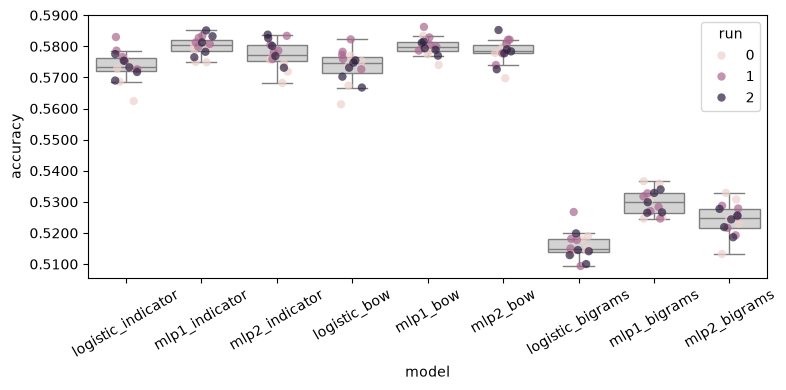

In [35]:
# The tutorial's plotter consumes {system: [per-seed run dicts]}.
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(grid))

### Motivating the ROPE (0.005)

We set the region of practical equivalence to ±0.005 accuracy because:
1. **Field convention:** in NLP, accuracy gains below ~0.5 points are routinely treated as
   practically uninteresting (the tutorial's stated rule of thumb). 
2. **Empirical noise floor:** our measured fold-to-fold std is ≈0.003–0.005 (and we
   pre-derived ≈0.0048 from the 40k working-set size). A mean difference smaller than our
   own measurement noise is not one we could act on, so ±0.005 is also where differences
   drop below our resolution. 

In [38]:
import numpy as np

ROPE = 0.005

def accs(key):
    # shape [seeds, folds] as BenavoliCorrelatedT expects (runs = n seeds)
    return np.array([list(r['accuracies'].values()) for r in grid[key]])

# Each comparison answers one research question. A = baseline, B = candidate.
comparisons = [
    ("Does order-alone help? (indicator vs bigrams, log-linear)",
     'logistic_indicator', 'logistic_bigrams'),
    ("Do counts help over presence? (indicator vs bow, mlp1)",
     'mlp1_indicator', 'mlp1_bow'),
    ("Does non-linearity help? (log-linear vs mlp1, indicator)",
     'logistic_indicator', 'mlp1_indicator'),
    ("Does depth help? (mlp1 vs mlp2, indicator)",
     'mlp1_indicator', 'mlp2_indicator'),
]

for title, a_key, b_key in comparisons:
    post = part1.analysis.BenavoliCorrelatedT(
        accs(a_key).flatten(), accs(b_key).flatten(),
        runs=len(grid[a_key]),                      # number of seeds
        names=[a_key, b_key],
    )
    pA, pTie, pB = post.probs(ROPE)
    print(f"\n{title}")
    print(f"  A={a_key}  B={b_key}")
    print(f"  P(A better)={pA:.3f}  P(practically equal)={pTie:.3f}  P(B better)={pB:.3f}"
          f"  | effect size={post.effect_size:.2f}")


Does order-alone help? (indicator vs bigrams, log-linear)
  A=logistic_indicator  B=logistic_bigrams
  P(A better)=1.000  P(practically equal)=0.000  P(B better)=0.000  | effect size=-17.65

Do counts help over presence? (indicator vs bow, mlp1)
  A=mlp1_indicator  B=mlp1_bow
  P(A better)=0.006  P(practically equal)=0.990  P(B better)=0.004  | effect size=-0.09

Does non-linearity help? (log-linear vs mlp1, indicator)
  A=logistic_indicator  B=mlp1_indicator
  P(A better)=0.000  P(practically equal)=0.275  P(B better)=0.724  | effect size=2.87

Does depth help? (mlp1 vs mlp2, indicator)
  A=mlp1_indicator  B=mlp2_indicator
  P(A better)=0.059  P(practically equal)=0.941  P(B better)=0.000  | effect size=-2.01


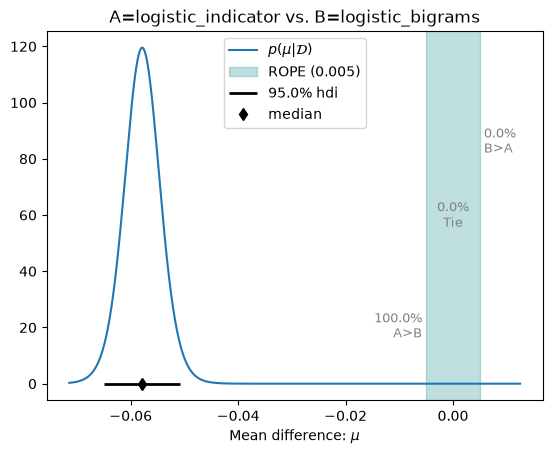

In [39]:
post = part1.analysis.BenavoliCorrelatedT(
    accs('logistic_indicator').flatten(), accs('logistic_bigrams').flatten(),
    runs=3, names=['logistic_indicator', 'logistic_bigrams'])
post.plot(ROPE)
import matplotlib.pyplot as plt; plt.show()

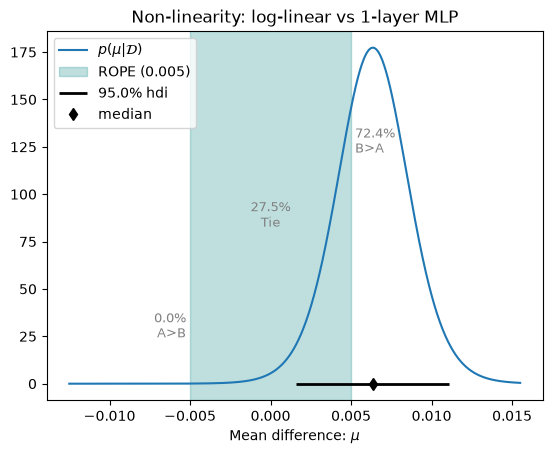

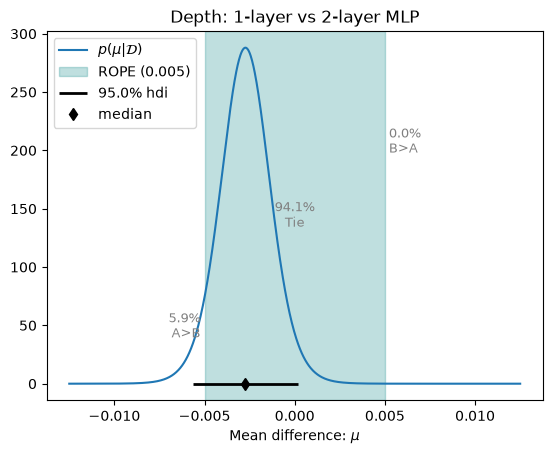

In [40]:
import matplotlib.pyplot as plt

ROPE = 0.005

def accs(key):
    return np.array([list(r['accuracies'].values()) for r in grid[key]])

borderline = [
    ('logistic_indicator', 'mlp1_indicator', "Non-linearity: log-linear vs 1-layer MLP"),
    ('mlp1_indicator',     'mlp2_indicator', "Depth: 1-layer vs 2-layer MLP"),
]

for a_key, b_key, title in borderline:
    post = part1.analysis.BenavoliCorrelatedT(
        accs(a_key).flatten(), accs(b_key).flatten(),
        runs=len(grid[a_key]), names=[a_key, b_key])
    post.plot(ROPE)
    plt.title(title)
    plt.show()

In [41]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

KEY = 'mlp1_indicator'
all_preds, all_golds = [], []

for seed_idx, seed in enumerate(MULTI_SEEDS):          # MULTI_SEEDS = [0,3,5]
    run = grid[KEY][seed_idx]
    cvset = cv_sets_by_seed[seed]
    for fold in cvset.keys():
        preds = run['predictions'][fold]
        golds = [lab for _, lab in cvset[fold]['validation']]
        assert len(preds) == len(golds), f"misalign seed {seed} fold {fold}"
        all_preds.extend(int(p) for p in preds)
        all_golds.extend(int(g) for g in golds)

names = list(snli_outcome_space.names)   # ['entailment','neutral','contradiction']
cm = confusion_matrix(all_golds, all_preds, labels=[0,1,2])

print(f"System: {KEY}  (pooled over {len(MULTI_SEEDS)} seeds × 5 folds, n={len(all_golds)})\n")
print("Confusion matrix (rows = gold, cols = predicted):")
print(f"{'':14s}" + "".join(f"{n[:12]:>14s}" for n in names))
for i, n in enumerate(names):
    print(f"{n:14s}" + "".join(f"{cm[i,j]:>14d}" for j in range(3)))

print("\nPer-class report:")
print(classification_report(all_golds, all_preds, labels=[0,1,2],
                            target_names=names, digits=4))

System: mlp1_indicator  (pooled over 3 seeds × 5 folds, n=120000)

Confusion matrix (rows = gold, cols = predicted):
                  entailment       neutral  contradictio
entailment             25230          6891          7947
neutral                 8482         22270          9166
contradiction           8860          9043         22111

Per-class report:
               precision    recall  f1-score   support

   entailment     0.5926    0.6297    0.6106     40068
      neutral     0.5829    0.5579    0.5701     39918
contradiction     0.5637    0.5526    0.5581     40014

     accuracy                         0.5801    120000
    macro avg     0.5798    0.5801    0.5796    120000
 weighted avg     0.5798    0.5801    0.5796    120000



### generate any system’s matrix

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

def show_confusion(KEY):
    all_preds, all_golds = [], []
    for seed_idx, seed in enumerate(MULTI_SEEDS):
        run = grid[KEY][seed_idx]
        cvset = cv_sets_by_seed[seed]
        for fold in cvset.keys():
            preds = run['predictions'][fold]
            golds = [lab for _, lab in cvset[fold]['validation']]
            assert len(preds) == len(golds), f"misalign {KEY} seed {seed} fold {fold}"
            all_preds.extend(int(p) for p in preds)
            all_golds.extend(int(g) for g in golds)

    names = list(snli_outcome_space.names)
    cm = confusion_matrix(all_golds, all_preds, labels=[0,1,2])
    print(f"System: {KEY}  (pooled {len(MULTI_SEEDS)} seeds × 5 folds, n={len(all_golds)})\n")
    print("Confusion matrix (rows=gold, cols=pred):")
    print(f"{'':14s}" + "".join(f"{n[:12]:>14s}" for n in names))
    for i, n in enumerate(names):
        print(f"{n:14s}" + "".join(f"{cm[i,j]:>14d}" for j in range(3)))
    print("\nPer-class report:")
    print(classification_report(all_golds, all_preds, labels=[0,1,2],
                                target_names=names, digits=4))
    print("="*60)



In [ ]:
show_confusion('mlp1_indicator')

In [ ]:

show_confusion('mlp1_bigrams')   # the failure case — how does it fail per-class?

### Results: Bayesian ROPE analysis and per-class behaviour

We compare systems with the Benavoli correlated-t estimation (tutorial's method) against
a ±0.005 ROPE, reporting P(A better) / P(practically equal) / P(B better) and the effect
size (mean difference in posterior-std units). Four comparisons, each answering one
research question:

**Order information in isolation is decisively worse (indicator vs bigrams).**
P(indicator better) = 1.000, effect size −17.6. The posterior sits ~6 points below zero,
nowhere near the ROPE. Bag-of-bigrams alone is far weaker than lexical presence: on short
NLI sentences (~7–12 tokens) bigram features are sparse (~7 fire per sentence) and, unlike
unigrams, discard the lexical signal entirely rather than augmenting it. This is why
Bowman (2015) used bigrams alongside unigrams and cross-features, never alone.

**Counts add nothing over presence (indicator vs bag-of-words).**
P(practically equal) = 0.990, effect size −0.09. Token counts are practically equivalent
to token presence which is expected on short sentences where tokens rarely repeat, so "how many"
≈ "whether". The Bayesian analysis puts 99% of the posterior inside the ROPE, so this is a
confident equivalence, not merely an unmeasured small difference.

**Non-linearity probably helps, but near the boundary (log-linear vs 1-layer MLP).**
P(MLP better) = 0.724, P(equal) = 0.275, effect size 2.87. The MLP's ~0.6-point gain is
consistent (large effect size → well-separated given our low fold noise), but its
magnitude straddles the ROPE: ~72% of the posterior mass exceeds our practical-interest
threshold, ~28% does not. We report this as a likely-but-borderline improvement rather
than overclaiming significance which is the kind of distinction the ROPE framing
expresses well (a frequentist test would report "significant" and hide the practical ambiguity).

**A second hidden layer does not help (1-layer vs 2-layer MLP).**
P(practically equal) = 0.941, effect size −2.01, with the small residual lean toward the
1-layer model. Classifier depth adds no practical value here, consistent with the SNLI
literature treating stacked layers as standard plumbing rather than a source of gains on
simple bag representations. (Effect size −2.0: the models are separable, but the difference is too small to clear the
ROPE.)

**Metric choice and per-class behaviour.** Accuracy is our headline metric, justified by
SNLI's class balance. we additionally report macro-F1 and the confusion matrix because the
informative errors are class-specific. Neutral is the weakest class by recall (0.558, vs
0.630 for entailment), and its errors split almost evenly into entailment (8,482) and
contradiction (9,166). entailment is both the strongest class (F1 0.611) and the most
over-predicted (~42.6k predictions against 40.1k true cases). This previews our artifact
analysis: neutral requires actually relating premise and hypothesis, whereas entailment and
contradiction carry lexical giveaways(eg words expressing contradiction):
the bias the hypothesis-only baseline further down will expose
directly.

**On effect size vs ROPE** A large effect size with a "practically
equal" verdict is not a contradiction: effect size measures how separated two systems'
posteriors are (which our low fold noise makes easy to resolve), while the ROPE asks
whether the size of that separation is worth acting on. Our 40k working set was sized so
fold noise (≈0.005) matches the ROPE, which is why small-but-consistent gains land right at
the boundary.

### EXTENSION


The design decision: should hypothesis-only use the exact same representation as the full model it’s compared against? Yes to make the comparison clean (same features, the only difference is it is now blind to the premise)

In [ ]:
class HypothesisOnly(CombinationRule):
    """Ignores the premise entirely and encodes only the hypothesis.
    Tests whether the hypothesis alone leaks the label (Gururangan 2018)."""
    def __call__(self, vp, vh):
        return vh                      # premise discarded
    def out_dim(self, d):
        return d                       # single-side dimension, not 2*d

### Hypothesis-only encoder

In [43]:
# --- Hypothesis-only encoder: indicator representation, premise discarded ---
hyp_only_enc = PairEncoder(CachedSide(cache_ind, TokenIndicatorFixed(tokenizer)),
                           HypothesisOnly())

# Smoke check: dimension is single-side (2000), and it ignores the premise.
(p, h), _ = working_set[0]
v = hyp_only_enc((p, h))
assert v.shape == (2000,), f"hyp-only dim should be 2000, got {v.shape}"
assert np.array_equal(v, CachedSide(cache_ind, TokenIndicatorFixed(tokenizer))(h)), \
    "hyp-only must equal encoding of the hypothesis alone"
# And a different premise with the same hypothesis gives the SAME vector:
assert np.array_equal(hyp_only_enc(("a totally different premise", h)), v), \
    "hyp-only must be invariant to the premise"
print("hypothesis-only encoder verified (dim 2000, premise-invariant). OK")

# --- Run hyp-only across the 3 architectures x 3 seeds, into `grid` ---
MLP_ARGS = {'hidden_dim': 128, 'dropout': 0.1, 'batch_size': 64,
            'learning_rate': 1e-4, 'weight_decay': 1e-4, 'num_epochs': 10}

for arch in ['logistic', 'mlp1', 'mlp2']:
    key = f"{arch}_hyponly"
    if key in grid:
        print(f"[skip] {key}"); continue
    runs = []
    for seed in MULTI_SEEDS:
        cvset = cv_sets_by_seed[seed]
        folder = f"{results_folder}/{key}/seed-{seed}"
        if arch == 'logistic':
            runs.append(experiment.cross_validation_experiment(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=hyp_only_enc,
                model_option='logistic', save_to=folder, loglin_args={'max_iter': 100}))
        elif arch == 'mlp1':
            runs.append(experiment.cross_validation_experiment(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=hyp_only_enc,
                model_option='mlp', save_to=folder, smlp_args=MLP_ARGS))
        else:
            runs.append(cv_experiment_2layer(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=hyp_only_enc,
                save_to=folder, smlp_args=MLP_ARGS))
    grid[key] = runs
    with open(CHECKPOINT, "wb") as f:   # same checkpoint safety
        pickle.dump(grid, f, protocol=pickle.HIGHEST_PROTOCOL)
    m = np.mean([np.mean(list(r['accuracies'].values())) for r in runs])
    print(f"[done] {key} | mean acc {m:.4f}")

hypothesis-only encoder verified (dim 2000, premise-invariant). OK


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  0%|          | 0/5 [00:00<?, ?it/s]

... (35 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0787 | train acc: 0.4300 | val loss: 1.0519 | val acc: 0.5088
Epoch 02 | train loss: 1.0103 | train acc: 0.5468 | val loss: 0.9793 | val acc: 0.5544
Epoch 03 | train loss: 0.9419 | train acc: 0.5806 | val loss: 0.9334 | val acc: 0.5704
Epoch 04 | train loss: 0.8965 | train acc: 0.6011 | val loss: 0.9117 | val acc: 0.5827
Epoch 05 | train loss: 0.8673 | train acc: 0.6160 | val loss: 0.8983 | val acc: 0.5904
Epoch 06 | train loss: 0.8465 | train acc: 0.6292 | val loss: 0.8914 | val acc: 0.5913
Epoch 07 | train loss: 0.8313 | train acc: 0.6349 | val loss: 0.8878 | val acc: 0.5938
Epoch 08 | train loss: 0.8203 | train acc: 0.6404 | val loss: 0.8857 | val acc: 0.5896
Epoch 09 | train loss: 0.8104 | train acc: 0.6445 | val loss: 0.8860 | val acc: 0.5924
Epoch 10 | train loss: 0.8016 | train acc: 0.6487 | val loss: 0.8859 | val acc: 0.5938
Training done! Time taken: 26.616 seconds
Transforming documents...
Document transformation done! Time taken: 0.059 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0790 | train acc: 0.4540 | val loss: 1.0547 | val acc: 0.5244
Epoch 02 | train loss: 1.0121 | train acc: 0.5472 | val loss: 0.9884 | val acc: 0.5464
Epoch 03 | train loss: 0.9425 | train acc: 0.5774 | val loss: 0.9461 | val acc: 0.5629
Epoch 04 | train loss: 0.8954 | train acc: 0.6013 | val loss: 0.9236 | val acc: 0.5743
Epoch 05 | train loss: 0.8648 | train acc: 0.6179 | val loss: 0.9118 | val acc: 0.5797
Epoch 06 | train loss: 0.8444 | train acc: 0.6294 | val loss: 0.9061 | val acc: 0.5853
Epoch 07 | train loss: 0.8293 | train acc: 0.6370 | val loss: 0.9034 | val acc: 0.5873
Epoch 08 | train loss: 0.8171 | train acc: 0.6423 | val loss: 0.9023 | val acc: 0.5875
Epoch 09 | train loss: 0.8076 | train acc: 0.6475 | val loss: 0.9023 | val acc: 0.5847
Epoch 10 | train loss: 0.7990 | train acc: 0.6501 | val loss: 0.9025 | val acc: 0.5843
Training done! Time taken: 27.485 seconds
[done] mlp1_hyponly | mean acc 0.5950
[done] mlp2_hyponly | mean acc 0.5948


hyp-only vs full (mlp1, indicator): P(hyponly better)=1.000  P(equal)=0.000  P(full better)=0.000 | effect=-7.40


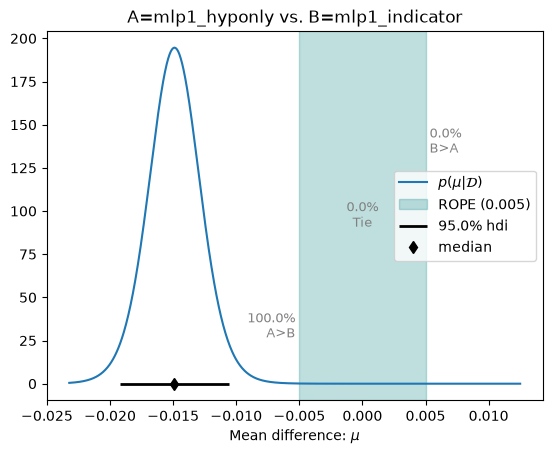

In [44]:
# Does the premise even help? full model vs hypothesis-only (indicator, mlp1).
post = part1.analysis.BenavoliCorrelatedT(
    accs('mlp1_hyponly').flatten(), accs('mlp1_indicator').flatten(),
    runs=3, names=['mlp1_hyponly', 'mlp1_indicator'])
pA, pTie, pB = post.probs(0.005)
print(f"hyp-only vs full (mlp1, indicator): "
      f"P(hyponly better)={pA:.3f}  P(equal)={pTie:.3f}  P(full better)={pB:.3f} "
      f"| effect={post.effect_size:.2f}")
post.plot(0.005); import matplotlib.pyplot as plt; plt.show()

In [ ]:
show_confusion('mlp1_hyponly')

### Ablation 2: cross-features (and why they don't help)

**Goal.** Test whether explicit premise × hypothesis interaction features help. Our
concatenation baseline gives the model both sentences' tokens in separate blocks, but a
linear model cannot form the product "token A in premise AND token B in hypothesis" on
its own. Cross-features hand it exactly those products (Bowman 2015's cross-unigrams). The
representation is `[premise unigrams, hypothesis unigrams, top-K cross-pairs]` —> unigrams
augmented with interaction, not replaced (we learned from bigrams that replacing lexical
content is fatal). Top-K = 4000 cross-pairs, selected by frequency with a deterministic
tie-break, fitted on training data only (→ dim 8000, matching our other interaction reps).

**Result: cross-features do not help.** Across all three architectures, cross-features
match the plain concatenation baseline (logistic 0.572 vs 0.574 indicator —> no gain). We
investigated rather than accepting the null:

1. **Ruled out convergence.** Re-running log-linear at 20× iterations (max_iter=2000) did
   not change the result (0.56), so it is not an under-fitting artifact.

2. **Diagnosed the cause —> uninformative features.** We measured each kept cross-feature's
   label skew (how far its label distribution departs from uniform). 44% of the top-4000
   cross-features are near-flat (fire ~equally across all three labels = useless) and only 12%
   are meaningfully discriminative. Frequency-selection keeps the common co-occurrences,
   which are also the least informative.

3. **Tested the obvious fix and it also failed.** We re-selected cross-features by
   informativeness (label skew) instead of frequency, computed per-fold on training data
   only (no leakage). This also did not help (0.575). So the problem is not feature
   selection.

**Conclusion: redundancy with the marginals.** Even the discriminative cross-features add
nothing, because the signal they carry is already available to the model through the
individual premise/hypothesis unigram blocks. This coheres with our hypothesis-only
finding: the label concentrates in simple lexical cues the model already sees, so explicit
interaction features are redundant. 

In [ ]:
### ABLATION 2

import numpy as np
from collections import Counter
from part1.clslib import Encoder

def build_cross_vocab(pairs, tokenizer, max_features=4000):
    """
    Top-K most frequent CROSS-unigram pairs (prem_token, hyp_token), where a
    cross-pair fires if prem_token is in the premise's token SET and hyp_token
    is in the hypothesis's token SET. Presence-based (type co-occurrence), not
    counts. Fitted on TRAINING data only; top-K + deterministic tie-break.
    Zipf tail dropped as un-estimable.
    """
    counts = Counter()
    for (prem, hyp), _ in pairs:
        p_ids = set(tokenizer.encode(prem).ids)   # distinct premise tokens
        h_ids = set(tokenizer.encode(hyp).ids)    # distinct hypothesis tokens
        for a in p_ids:
            for b in h_ids:
                counts[(a, b)] += 1
    ranked = sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))
    kept = [pair for pair, _ in ranked[:max_features]]
    cross_index = {pair: i for i, pair in enumerate(kept)}
    min_kept = counts[kept[-1]] if kept else 0
    print(f"distinct cross-pairs: {len(counts)} | kept top-{max_features} "
          f"| implied min count: {min_kept}")
    return cross_index


class CrossFeatures(Encoder):
    """
    Pair encoder: [premise unigram-indicators, hypothesis unigram-indicators,
    top-K cross-pair indicators]. Augments unigrams with explicit premise x
    hypothesis interaction features (Bowman 2015's cross-unigrams). Takes a (premise,
    hypothesis) tuple directly; does NOT use the CombinationRule abstraction,
    because cross-features need both token sets jointly, not the final vectors.
    """
    def __init__(self, tokenizer, cross_index: dict):
        self.tokenizer = tokenizer
        self.cross_index = cross_index
        self.V = len(tokenizer.get_vocab())   # single-side unigram dim

    def __len__(self):
        return 2 * self.V + len(self.cross_index)   # prem uni + hyp uni + cross

    def __call__(self, pair):
        prem, hyp = pair
        p_ids = set(self.tokenizer.encode(prem).ids)
        h_ids = set(self.tokenizer.encode(hyp).ids)

        vec = np.zeros(len(self), dtype=np.float32)
        # Block 1: premise unigram indicators  [0 : V)
        for i in p_ids:
            vec[i] = 1.0
        # Block 2: hypothesis unigram indicators  [V : 2V)
        for i in h_ids:
            vec[self.V + i] = 1.0
        # Block 3: cross-pair indicators  [2V : 2V + K)
        base = 2 * self.V
        for a in p_ids:
            for b in h_ids:
                idx = self.cross_index.get((a, b))
                if idx is not None:
                    vec[base + idx] = 1.0
        return vec

In [46]:
#  smoke test 

cross_index = build_cross_vocab(working_set, tokenizer, max_features=4000)

# Smoke test: dimension, and that it genuinely uses BOTH sentences.
cross_enc = CrossFeatures(tokenizer, cross_index)
D = len(cross_enc)
print(f"cross-feature dim: {D}  (expect 2*2000 + 4000 = 8000)")
assert D == 2 * 2000 + 4000

(p, h), _ = working_set[0]
v = cross_enc((p, h))
V = 2000
print(f"premise-block nz: {int(v[:V].sum())}  hyp-block nz: {int(v[V:2*V].sum())}  "
      f"cross-block nz: {int(v[2*V:].sum())}")
# Changing the premise must change the premise block AND the cross block,
# but leave the hypothesis block identical:
v2 = cross_enc(("a dog runs in a field", h))
assert np.array_equal(v[V:2*V], v2[V:2*V]), "hyp block should be premise-invariant"
assert not np.array_equal(v[:V], v2[:V]), "premise block must change with premise"
print("cross-feature encoder verified (uses both sentences; blocks correct). OK")

distinct cross-pairs: 1082860 | kept top-4000 | implied min count: 140
cross-feature dim: 8000  (expect 2*2000 + 4000 = 8000)
premise-block nz: 17  hyp-block nz: 8  cross-block nz: 46
cross-feature encoder verified (uses both sentences; blocks correct). OK


In [51]:
cross_enc = CrossFeatures(tokenizer, cross_index)   # the pair encoder (no PairEncoder wrapper needed)

MLP_ARGS = {'hidden_dim': 128, 'dropout': 0.1, 'batch_size': 64,
            'learning_rate': 1e-4, 'weight_decay': 1e-4, 'num_epochs': 10}

for arch in ['logistic', 'mlp1', 'mlp2']:
    key = f"{arch}_cross"
    if key in grid:
        print(f"[skip] {key}"); continue
    runs = []
    for seed in MULTI_SEEDS:
        cvset = cv_sets_by_seed[seed]
        folder = f"{results_folder}/{key}/seed-{seed}"
        if arch == 'logistic':
            runs.append(experiment.cross_validation_experiment(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=cross_enc,
                model_option='logistic', save_to=folder, loglin_args={'max_iter': 100}))
        elif arch == 'mlp1':
            runs.append(experiment.cross_validation_experiment(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=cross_enc,
                model_option='mlp', save_to=folder, smlp_args=MLP_ARGS))
        else:
            runs.append(cv_experiment_2layer(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=cross_enc,
                save_to=folder, smlp_args=MLP_ARGS))
    grid[key] = runs
    with open(CHECKPOINT, "wb") as f:
        pickle.dump(grid, f, protocol=pickle.HIGHEST_PROTOCOL)
    m = np.mean([np.mean(list(r['accuracies'].values())) for r in runs])
    print(f"[done] {key} | mean acc {m:.4f}")

[skip] logistic_cross
[skip] mlp1_cross
[done] mlp2_cross | mean acc 0.5840


In [48]:
from sklearn.metrics import accuracy_score
tr = cv_sets_by_seed[0][0]['training']; va = cv_sets_by_seed[0][0]['validation']
m = loglin.fit(tr, cross_enc, save_to=None, max_iter=2000)   # 20x iterations
preds = loglin.predict([t for t,_ in va], m, cross_enc)
print("cross logistic @ max_iter=2000:", accuracy_score([l for _,l in va], preds))

cross logistic @ max_iter=2000: 0.5635


In [49]:
import numpy as np
from collections import defaultdict

# For each kept cross-feature, how does its firing distribute across the 3 labels?
# If cross-features are informative, some should fire much more for one label.
# If they're frequent-but-flat, they fire ~evenly across labels (uninformative).

# Count label co-occurrence for each cross-feature on the working set.
fire_by_label = defaultdict(lambda: np.zeros(3))   # cross_idx -> [n_entail, n_neutral, n_contra]
label_totals = np.zeros(3)

for (prem, hyp), lab in working_set:
    label_totals[lab] += 1
    p_ids = set(tokenizer.encode(prem).ids)
    h_ids = set(tokenizer.encode(hyp).ids)
    fired = set()
    for a in p_ids:
        for b in h_ids:
            idx = cross_index.get((a, b))
            if idx is not None:
                fired.add(idx)
    for idx in fired:
        fire_by_label[idx][lab] += 1

# For each cross-feature, measure how skewed its label distribution is.
# A feature that fires equally across labels (skew ~0) is uninformative.
skews = []
for idx, counts in fire_by_label.items():
    total = counts.sum()
    if total >= 50:                      # ignore ultra-rare for stability
        p = counts / total              # label distribution given the feature fired
        # max deviation from uniform (1/3): 0 = flat/useless, high = discriminative
        skews.append(p.max() - 1/3)
skews = np.array(skews)

print(f"cross-features analyzed: {len(skews)}")
print(f"label-skew (max class prob - 1/3):  mean={skews.mean():.3f}  median={np.median(skews):.3f}  max={skews.max():.3f}")
print(f"features that are near-flat (skew < 0.05): {int((skews < 0.05).sum())} / {len(skews)}")
print(f"features meaningfully skewed (skew > 0.15): {int((skews > 0.15).sum())} / {len(skews)}")


cross-features analyzed: 4000
label-skew (max class prob - 1/3):  mean=0.078  median=0.056  max=0.497
features that are near-flat (skew < 0.05): 1776 / 4000
features meaningfully skewed (skew > 0.15): 497 / 4000


In [50]:
import numpy as np
from collections import defaultdict, Counter
from sklearn.metrics import accuracy_score

def build_informative_cross_vocab(train_pairs, tokenizer, max_features=4000, min_fire=50):
    """
    Select top cross-features by LABEL INFORMATIVENESS (skew), not frequency.
    skew = max_label_prob - 1/3, computed on TRAIN PAIRS ONLY (per-fold -> no leakage).
    Only considers features firing >= min_fire times (skew is unstable for rare ones).
    """
    fire_by_label = defaultdict(lambda: np.zeros(3))
    for (prem, hyp), lab in train_pairs:
        p_ids = set(tokenizer.encode(prem).ids)
        h_ids = set(tokenizer.encode(hyp).ids)
        for a in p_ids:
            for b in h_ids:
                fire_by_label[(a, b)][lab] += 1

    scored = []
    for pair, counts in fire_by_label.items():
        total = counts.sum()
        if total >= min_fire:
            skew = (counts / total).max() - 1/3
            scored.append((skew, pair))
    # Top-K by skew; tie-break deterministically on the pair.
    scored.sort(key=lambda sp: (-sp[0], sp[1]))
    kept = [pair for _, pair in scored[:max_features]]
    return {pair: i for i, pair in enumerate(kept)}


def cv_experiment_informative_cross(data_splits, outcome_space, tokenizer,
                                    max_features=4000, min_fire=50, max_iter=100):
    """
    Per-fold CV for the informativeness-selected cross-feature log-linear model.
    Cross-vocab is rebuilt on each fold's TRAINING set only -> no label leakage.
    Mirrors cross_validation_experiment's 'logistic' branch otherwise.
    """
    accuracies, predictions = {}, {}
    for fold in data_splits.keys():
        tr = data_splits[fold]["training"]
        va = data_splits[fold]["validation"]

        # Feature selection on TRAIN ONLY.
        cross_idx = build_informative_cross_vocab(tr, tokenizer, max_features, min_fire)
        enc = CrossFeatures(tokenizer, cross_idx)   # reuse the same encoder, new vocab

        m = loglin.fit(tr, enc, save_to=None, max_iter=max_iter)
        preds = loglin.predict([t for t, _ in va], m, enc)
        golds = [l for _, l in va]
        predictions[fold] = preds
        accuracies[fold] = accuracy_score(golds, preds)
    return {'accuracies': accuracies, 'predictions': predictions}


# --- Run informativeness-selected cross-features, log-linear, 3 seeds ---
key = 'logistic_cross_informative'
if key not in grid:
    runs = []
    for seed in MULTI_SEEDS:
        runs.append(cv_experiment_informative_cross(
            cv_sets_by_seed[seed], snli_outcome_space, tokenizer,
            max_features=4000, min_fire=50, max_iter=100))
        m = np.mean(list(runs[-1]['accuracies'].values()))
        print(f"  seed {seed}: {m:.4f}")
    grid[key] = runs
    with open(CHECKPOINT, "wb") as f:
        pickle.dump(grid, f, protocol=pickle.HIGHEST_PROTOCOL)
    mean = np.mean([np.mean(list(r['accuracies'].values())) for r in runs])
    print(f"[done] {key} | mean acc {mean:.4f}")

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  seed 0: 0.5739


c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  seed 3: 0.5740


c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  seed 5: 0.5764
[done] logistic_cross_informative | mean acc 0.5748


### Show results


In [ ]:
import pickle
import numpy as np

# Load grid from checkpoint if it's not in memory (e.g. after a kernel restart).
try:
    grid
except NameError:
    with open(CHECKPOINT, "rb") as f:
        grid = pickle.load(f)

ABLATION2 = ['logistic_cross', 'mlp1_cross', 'mlp2_cross', 'logistic_cross_informative']

print("Ablation 2 — cross-features (pooled over seeds × folds):\n")
print(f"{'system':28s} {'mean':>8} {'std':>8}  {'n':>4}")
print("-" * 52)
for key in ABLATION2:
    if key not in grid:
        print(f"{key:28s}  (not in grid)")
        continue
    accs = np.array([list(r['accuracies'].values()) for r in grid[key]]).flatten()
    print(f"{key:28s} {accs.mean():>8.4f} {accs.std():>8.4f}  {len(accs):>4}")

# For reference: the baseline these are compared against.
base = np.array([list(r['accuracies'].values()) for r in grid['logistic_indicator']]).flatten()
print("-" * 52)
print(f"{'(baseline) logistic_indicator':28s} {base.mean():>8.4f} {base.std():>8.4f}  {len(base):>4}")

## diff/product across the grid

In [52]:
# ConcatDiffProd already defined in the PairEncoder design.  
# Dim = 4 * 2000 = 8000 (comparable to cross and bigrams).
dp_enc = PairEncoder(CachedSide(cache_ind, TokenIndicatorFixed(tokenizer)), ConcatDiffProd())

# Smoke check: dim and that it uses both sentences.
(p, h), _ = working_set[0]
assert dp_enc((p, h)).shape == (8000,), "diff/product dim should be 4*2000=8000"
print("diff/product encoder OK, dim 8000")

MLP_ARGS = {'hidden_dim': 128, 'dropout': 0.1, 'batch_size': 64,
            'learning_rate': 1e-4, 'weight_decay': 1e-4, 'num_epochs': 10}

for arch in ['logistic', 'mlp1', 'mlp2']:
    key = f"{arch}_diffprod"
    if key in grid:
        print(f"[skip] {key}"); continue
    runs = []
    for seed in MULTI_SEEDS:
        cvset = cv_sets_by_seed[seed]
        folder = f"{results_folder}/{key}/seed-{seed}"
        if arch == 'logistic':
            runs.append(experiment.cross_validation_experiment(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=dp_enc,
                model_option='logistic', save_to=folder, loglin_args={'max_iter': 100}))
        elif arch == 'mlp1':
            runs.append(experiment.cross_validation_experiment(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=dp_enc,
                model_option='mlp', save_to=folder, smlp_args=MLP_ARGS))
        else:
            runs.append(cv_experiment_2layer(
                data_splits=cvset, outcome_space=snli_outcome_space, encoder=dp_enc,
                save_to=folder, smlp_args=MLP_ARGS))
    grid[key] = runs
    with open(CHECKPOINT, "wb") as f:
        pickle.dump(grid, f, protocol=pickle.HIGHEST_PROTOCOL)
    m = np.mean([np.mean(list(r['accuracies'].values())) for r in runs])
    print(f"[done] {key} | mean acc {m:.4f}")

diff/product encoder OK, dim 8000


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  0%|          | 0/5 [00:00<?, ?it/s]

... (34 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0570 | train acc: 0.4842 | val loss: 0.9933 | val acc: 0.5655
Epoch 02 | train loss: 0.9130 | train acc: 0.6167 | val loss: 0.8972 | val acc: 0.6044
Epoch 03 | train loss: 0.8098 | train acc: 0.6644 | val loss: 0.8581 | val acc: 0.6174
Epoch 04 | train loss: 0.7504 | train acc: 0.6902 | val loss: 0.8430 | val acc: 0.6222
Epoch 05 | train loss: 0.7079 | train acc: 0.7105 | val loss: 0.8373 | val acc: 0.6250
Epoch 06 | train loss: 0.6755 | train acc: 0.7253 | val loss: 0.8390 | val acc: 0.6272
Epoch 07 | train loss: 0.6508 | train acc: 0.7378 | val loss: 0.8408 | val acc: 0.6300
Epoch 08 | train loss: 0.6281 | train acc: 0.7463 | val loss: 0.8480 | val acc: 0.6336
Epoch 09 | train loss: 0.6069 | train acc: 0.7565 | val loss: 0.8554 | val acc: 0.6274
Epoch 10 | train loss: 0.5875 | train acc: 0.7658 | val loss: 0.8590 | val acc: 0.6344
Training done! Time taken: 41.247 seconds
Transforming documents...
Document transformation done! Time taken: 0.887 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0560 | train acc: 0.4858 | val loss: 0.9949 | val acc: 0.5596
Epoch 02 | train loss: 0.9119 | train acc: 0.6188 | val loss: 0.8984 | val acc: 0.6009
Epoch 03 | train loss: 0.8109 | train acc: 0.6629 | val loss: 0.8582 | val acc: 0.6184
Epoch 04 | train loss: 0.7514 | train acc: 0.6887 | val loss: 0.8401 | val acc: 0.6254
Epoch 05 | train loss: 0.7116 | train acc: 0.7073 | val loss: 0.8364 | val acc: 0.6270
Epoch 06 | train loss: 0.6789 | train acc: 0.7221 | val loss: 0.8325 | val acc: 0.6305
Epoch 07 | train loss: 0.6536 | train acc: 0.7318 | val loss: 0.8335 | val acc: 0.6290
Epoch 08 | train loss: 0.6313 | train acc: 0.7430 | val loss: 0.8384 | val acc: 0.6311
Epoch 09 | train loss: 0.6119 | train acc: 0.7515 | val loss: 0.8401 | val acc: 0.6315
Epoch 10 | train loss: 0.5928 | train acc: 0.7586 | val loss: 0.8456 | val acc: 0.6286
Training done! Time taken: 41.668 seconds
[done] mlp1_diffprod | mean acc 0.6318
[done] mlp2_diffprod | mean acc 0.6289


In [ ]:
show_confusion('mlp1_diffprod')     # +overlap features 

## Learning curve

In [58]:
import pickle
from pathlib import Path
from sklearn.model_selection import train_test_split

SIZES = [10_000, 20_000, 40_000]
LC_SEEDS = [0, 3, 5]
LC_CKPT = Path(f"{results_folder}/lc_checkpoint.pkl")

# Resume if partial progress exists.
if LC_CKPT.exists():
    with open(LC_CKPT, "rb") as f:
        lc_results = pickle.load(f)
    print("Resumed. Done so far:", list(lc_results.keys()))
else:
    lc_results = {}

def subsample(pairs, size, seed):
    if size >= len(pairs):
        return pairs
    X = [ph for ph, _ in pairs]; y = [lab for _, lab in pairs]
    Xs, _, ys, _ = train_test_split(X, y, train_size=size, stratify=y, random_state=seed)
    return list(zip(Xs, ys))

for size in SIZES:
    for sysname, arch in [('logistic_indicator', 'logistic'), ('mlp1_indicator', 'mlp1')]:
        if (sysname, size) in lc_results:
            print(f"[skip] {sysname} size={size}"); continue
        accs_over_seeds = []
        for seed in LC_SEEDS:
            sub = subsample(working_set, size, seed)
            cvset = experiment.cross_validation_split(sub, k=5, seed=seed)
            enc = PairEncoder(CachedSide(cache_ind, TokenIndicatorFixed(tokenizer)), Concat())
            opt = dict(data_splits=cvset, outcome_space=snli_outcome_space, encoder=enc,
                       save_to=f"{results_folder}/lc/{sysname}_{size}_{seed}")
            if arch == 'logistic':
                r = experiment.cross_validation_experiment(**opt, model_option='logistic',
                                                           loglin_args={'max_iter': 100})
            else:
                r = experiment.cross_validation_experiment(**opt, model_option='mlp',
                                                           smlp_args=MLP_ARGS)
            accs_over_seeds.append(np.mean(list(r['accuracies'].values())))
        lc_results[(sysname, size)] = accs_over_seeds
        with open(LC_CKPT, "wb") as f:
            pickle.dump(lc_results, f)
        print(f"[done] {sysname:20s} size={size:>6} : mean {np.mean(accs_over_seeds):.4f}")

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\admin\Documents\MSC_STUFFS\NLP\nlp1-student-tutorial1-2026\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


... (120 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0810 | train acc: 0.4198 | val loss: 1.0504 | val acc: 0.5106
Epoch 02 | train loss: 1.0003 | train acc: 0.5515 | val loss: 0.9771 | val acc: 0.5503
Epoch 03 | train loss: 0.9234 | train acc: 0.5939 | val loss: 0.9383 | val acc: 0.5667
Epoch 04 | train loss: 0.8709 | train acc: 0.6207 | val loss: 0.9212 | val acc: 0.5747
Epoch 05 | train loss: 0.8331 | train acc: 0.6383 | val loss: 0.9120 | val acc: 0.5786
Epoch 06 | train loss: 0.8056 | train acc: 0.6534 | val loss: 0.9084 | val acc: 0.5771
Epoch 07 | train loss: 0.7840 | train acc: 0.6629 | val loss: 0.9076 | val acc: 0.5795
Epoch 08 | train loss: 0.7644 | train acc: 0.6747 | val loss: 0.9092 | val acc: 0.5810
Epoch 09 | train loss: 0.7485 | train acc: 0.6815 | val loss: 0.9131 | val acc: 0.5837
Epoch 10 | train loss: 0.7337 | train acc: 0.6870 | val loss: 0.9159 | val acc: 0.5841
Training done! Time taken: 41.062 seconds
Transforming documents...
Document transformation done! Time taken: 0.281 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0803 | train acc: 0.4380 | val loss: 1.0519 | val acc: 0.5159
Epoch 02 | train loss: 0.9979 | train acc: 0.5594 | val loss: 0.9802 | val acc: 0.5481
Epoch 03 | train loss: 0.9190 | train acc: 0.5952 | val loss: 0.9420 | val acc: 0.5637
Epoch 04 | train loss: 0.8666 | train acc: 0.6203 | val loss: 0.9235 | val acc: 0.5719
Epoch 05 | train loss: 0.8292 | train acc: 0.6418 | val loss: 0.9153 | val acc: 0.5746
Epoch 06 | train loss: 0.8016 | train acc: 0.6541 | val loss: 0.9120 | val acc: 0.5759
Epoch 07 | train loss: 0.7800 | train acc: 0.6648 | val loss: 0.9117 | val acc: 0.5773
Epoch 08 | train loss: 0.7624 | train acc: 0.6726 | val loss: 0.9135 | val acc: 0.5759
Epoch 09 | train loss: 0.7457 | train acc: 0.6820 | val loss: 0.9159 | val acc: 0.5771
Epoch 10 | train loss: 0.7320 | train acc: 0.6896 | val loss: 0.9192 | val acc: 0.5760
Training done! Time taken: 41.186 seconds
[done] mlp1_indicator       size= 40000 : mean 0.5795


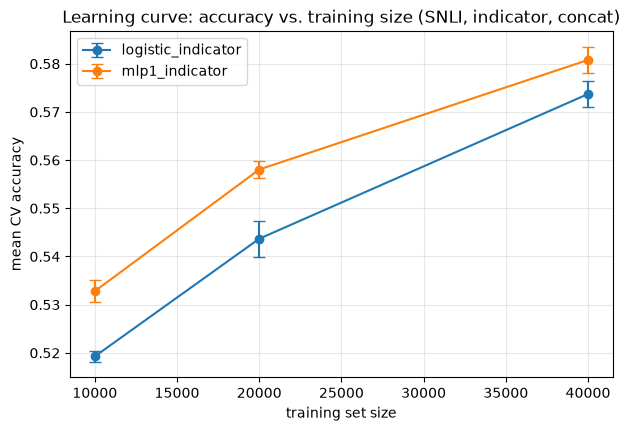

In [57]:
# Plot the learning curve.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7,4.5))
for sysname in ['logistic_indicator', 'mlp1_indicator']:
    means = [np.mean(lc_results[(sysname, s)]) for s in SIZES]
    stds  = [np.std(lc_results[(sysname, s)])  for s in SIZES]
    ax.errorbar(SIZES, means, yerr=stds, marker='o', capsize=4, label=sysname)
ax.set_xlabel("training set size"); ax.set_ylabel("mean CV accuracy")
ax.set_title("Learning curve: accuracy vs. training size (SNLI, indicator, concat)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

In [ ]:
# ============ FINAL TEST-SET EVALUATION (best system, once) ============
# Best system = diff/product representation, 1-layer MLP (top grid accuracy).
# CV was for comparison - for the final number we train on ALL 40k and evaluate
# once on the untouched, identically-cleaned SNLI test split.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# --- Load + clean the test split with the SAME two-part filter as training ---
test_pairs = [
    ((ex["premise"], ex["hypothesis"]), ex["label"])
    for ex in snli["test"]
    if ex["label"] != -1
    and not (ex["premise"] == ex["hypothesis"] and ex["label"] != 0)
]
print(f"Test pairs after cleaning (-1 and identical-mislabels): {len(test_pairs)}")
from collections import Counter
print("Test label dist (0/1/2):", dict(sorted(Counter(l for _, l in test_pairs).items())))

# --- The best encoder: diff/product on indicator (same as mlp1_diffprod) ---
best_enc = PairEncoder(CachedSide(cache_ind, TokenIndicatorFixed(tokenizer)), ConcatDiffProd())

# --- Train on ALL 40k (no CV), evaluate once on test ---
MLP_ARGS = {'hidden_dim': 128, 'dropout': 0.1, 'batch_size': 64,
            'learning_rate': 1e-4, 'weight_decay': 1e-4, 'num_epochs': 10}

# train_neural_network_model needs a validation set for its best-epoch checkpoint;
# use a small held-out slice OF THE 40k (not test) purely for epoch selection.
from sklearn.model_selection import train_test_split as _tts
Xtr = [ph for ph, _ in working_set]; ytr = [l for _, l in working_set]
Xa, Xb, ya, yb = _tts(Xtr, ytr, test_size=0.1, stratify=ytr, random_state=0)
train_final = list(zip(Xa, ya))      # 36k for training
valsel_final = list(zip(Xb, yb))     # 4k for epoch selection only

metrics, best_epoch, _ = smlp.train_neural_network_model(
    train_final, valsel_final, num_classes=len(snli_outcome_space),
    encoder=best_enc, save_to=f"{results_folder}/FINAL_mlp1_diffprod",
    **MLP_ARGS)
print(f"Best epoch (by val-selection slice): {best_epoch}")

# --- Load the checkpointed best model, predict on TEST ---
final_model = smlp.load(f"{results_folder}/FINAL_mlp1_diffprod")
test_preds = smlp.predict_probs([t for t, _ in test_pairs], final_model, best_enc).argmax(axis=1)
test_golds = [l for _, l in test_pairs]

# --- The headline number + per-class breakdown ---
acc = accuracy_score(test_golds, test_preds)
print(f"\n{'='*50}\nFINAL TEST ACCURACY (mlp1_diffprod): {acc:.4f}\n{'='*50}\n")
names = list(snli_outcome_space.names)
print(classification_report(test_golds, test_preds, labels=[0,1,2],
                            target_names=names, digits=4))
print("Confusion matrix (rows=gold, cols=pred):")
cm = confusion_matrix(test_golds, test_preds, labels=[0,1,2])
print(f"{'':14s}" + "".join(f"{n[:12]:>14s}" for n in names))
for i, n in enumerate(names):
    print(f"{n:14s}" + "".join(f"{cm[i,j]:>14d}" for j in range(3)))

Test pairs after cleaning (-1 and identical-mislabels): 9824
Test label dist (0/1/2): {0: 3368, 1: 3219, 2: 3237}
Transforming documents...
Document transformation done! Time taken: 1.132 seconds
Dataloader done! Time taken: 1.918 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0506 | train acc: 0.4888 | val loss: 0.9788 | val acc: 0.5767
Epoch 02 | train loss: 0.8979 | train acc: 0.6200 | val loss: 0.8776 | val acc: 0.6170
Epoch 03 | train loss: 0.8021 | train acc: 0.6628 | val loss: 0.8388 | val acc: 0.6355
Epoch 04 | train loss: 0.7480 | train acc: 0.6872 | val loss: 0.8231 | val acc: 0.6370
Epoch 05 | train loss: 0.7094 | train acc: 0.7045 | val loss: 0.8172 | val acc: 0.6382
Epoch 06 | train loss: 0.6819 | train acc: 0.7181 | val loss: 0.8143 | val acc: 0.6448
Epoch 07 | train loss: 0.6575 | train acc: 0.7266 | val loss: 0.8163 | val acc: 0.6392
Epoch 08 | train loss: 0.6375 | train acc: 0.7365 | val loss: 0.8188 | val acc: 0.6432
Epoch 09 | train loss: 0.6189 | train acc: 0.7462 | val loss: 0.8247 | val acc: 0.6382
Epoch 10 | train loss: 0.6009 | train acc: 0.7535 | val loss: 0.8293 | val acc: 0.6418
Training done! Time taken: 45.805 seconds
Best epoch (by val-selection slice): 5

FINAL TEST ACCURACY (mlp1_diffprod): 0.6546

   

In [ ]:
# %% [markdown]
# ## TODO / open threads

# REPORT CONFUSION MATRICES: I MUST DO THIS ONCE I GO HOME BECAUSE THAT IS WHERE THE SYSTEM TRAINED AND I HAVE THE RESULTS: SCREENSHOT
show_confusion('mlp1_indicator')
show_confusion('mlp1_bigrams')   # the failure case — how does it fail per-class?
show_confusion('mlp1_hyponly') #and put it side by side with the indicator one



 

# TODO CALL THE ABLATION 2 CELL TO PRINT THE ACCURACY METRICS 
# ABLATION2 = ['logistic_cross', 'mlp1_cross', 'mlp2_cross', 'logistic_cross_informative']

show_confusion('mlp1_diffprod')     # +overlap features 

 
# ### Other considerations (out of scope)
# - [ ] NLTK word-level tokenizer experiment: build the matching encoder, run at one grid
#       cell, show BPE-vs-word-level lands in the same ROPE (tokenizer choice doesn't move
#       conclusions).  
# NLTK experiment!
  
# ### Extension ideas for the architecture axis 
# - [ ] **Leaky ReLU variant.** The iterative-refinement NLI paper (Talman et al. 2018)
#       swaps ReLU -> Leaky ReLU to stop gradients dying for x<0. Motivated on our sparse
#       high-dim inputs (dead-unit risk). Cheap: one-line activation change in SparseMLP2.
# - [ ] **Skip-connection / refinement MLP.** The same lineage's core idea: a deeper layer
#       that also sees the original input (2nd layer input = [hidden_1, raw_input]), rather
#       than pure stacking. Tests whether direct access to raw features helps on sparse NLI.
# - [x] COMMITTED third architecture: two-hidden-layer MLP (field-standard SNLI classifier
#       depth; isolates depth as the variable). Required grid uses this.